<a href="https://colab.research.google.com/github/kara04y/2026_Intro_Python/blob/main/FEEDBACK_KARA_YENNY_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feedback : Exercice 1.6

In [2]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

print(states_path)

/root/.cache/mlees/us_states.geojson


In [3]:
# Q1 : Import geopandas (as gpd), pandas, and matplotlib
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Q2 : Read the data with the geopandasfunction
country = gpd.read_file(states_path)
country.head()

# Q3 : # Print out the first few lines of the data
print(country.geometry.head(5)) # It contains multipolygons and polygons


0    MULTIPOLYGON (((-88.12466 30.28364, -88.08681 ...
1    MULTIPOLYGON (((-166.10574 53.98861, -166.0752...
2    POLYGON ((-112.53859 37.00067, -112.53454 37.0...
3    POLYGON ((-94.04296 33.01922, -94.04304 33.079...
4    MULTIPOLYGON (((-122.42144 37.86997, -122.4213...
Name: geometry, dtype: geometry


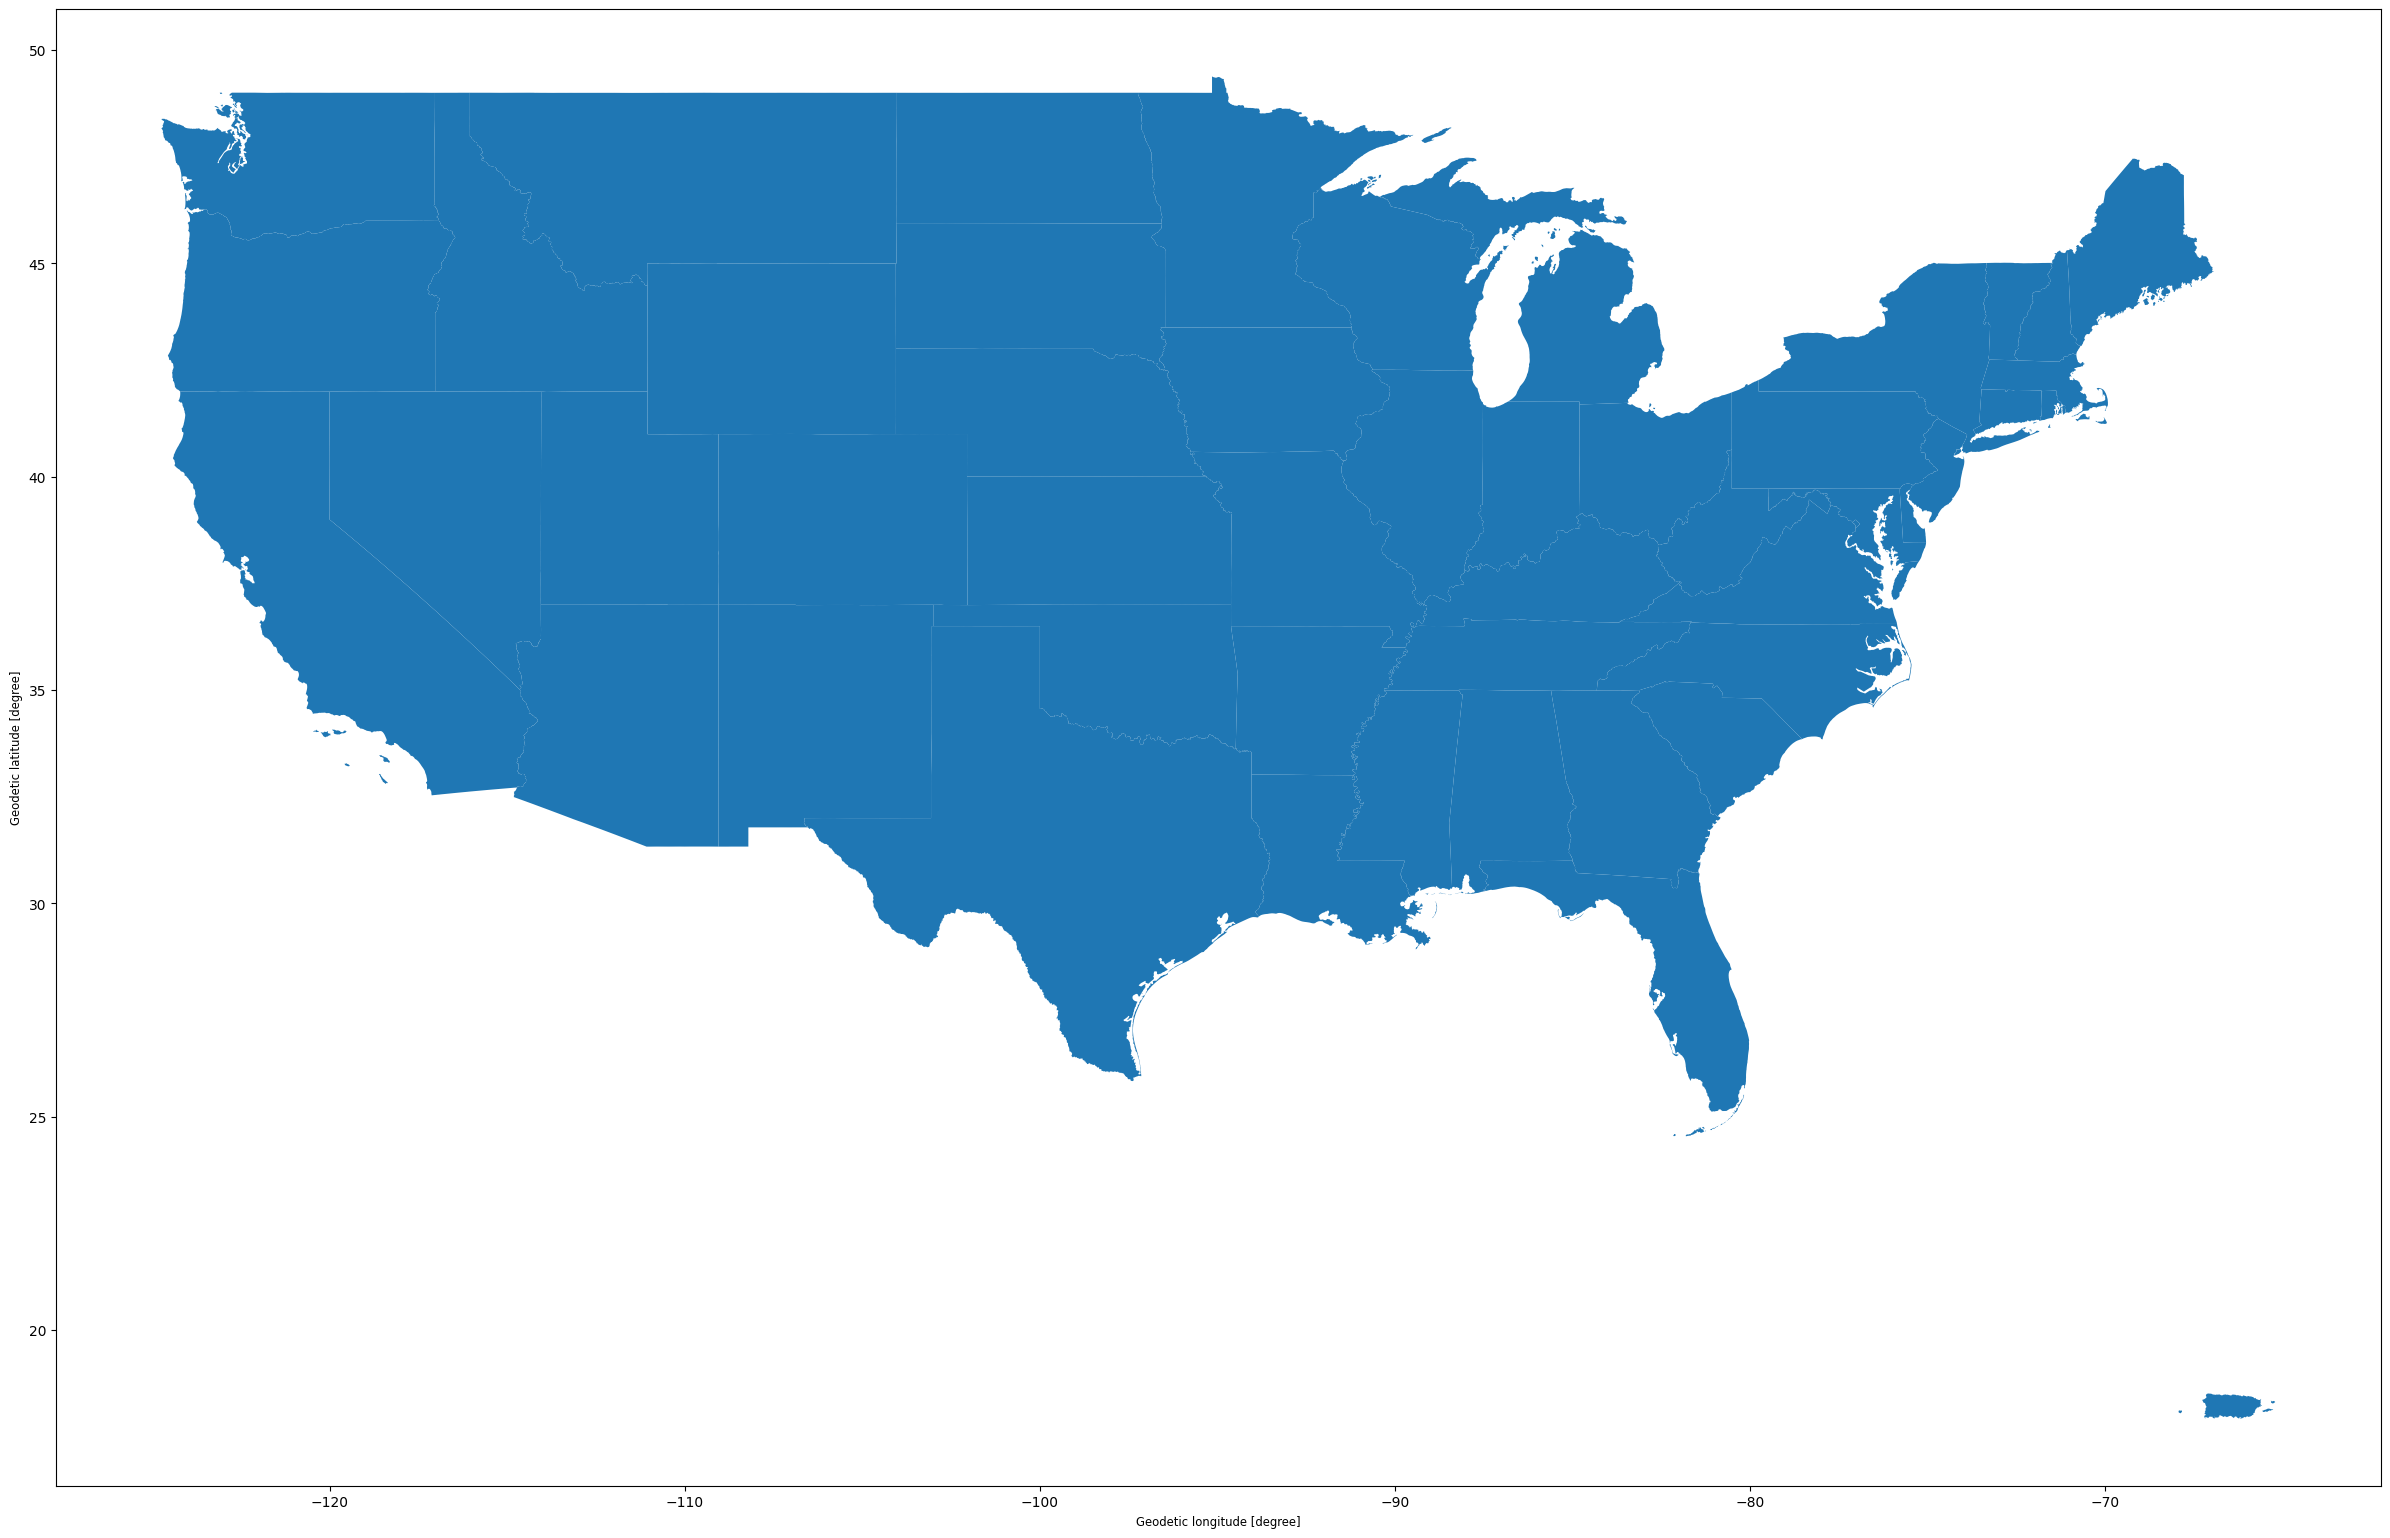

In [4]:
# Q4 : Plot the US states (Alaska and Hawaii excluded)
US = country[~country["NAME"].isin(["Alaska","Hawaii"])].plot(figsize=(30,20))

In [5]:
# Pre-supplied: read in the hurricane Florence data, drop the advisory bookkeeping columns,
# fix the longitude sign, and have a look at the dataframe.
# The Long column holds a positive "degrees west" magnitude, not a signed longitude -- a common
# quirk of NHC advisory data.

florence = pd.read_csv(track_path)
florence = florence.drop(["AdvisoryNumber", "Forecaster", "Received"], axis=1)
florence["Long"] = 0 - florence["Long"]
florence.head(3)

,Date,Lat,Long,Wind,Pres,Movement,Type,Name
0,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
1,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six


In [6]:
# Q5 : Create a geodataframe from the hurricane florence dataframe
gdf_florence = gpd.GeoDataFrame(
    florence,
    geometry = gpd.points_from_xy(florence["Long"], florence["Lat"]),
    crs="EPSG:4326"
)
track_path

'/root/.cache/mlees/florence.csv'

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

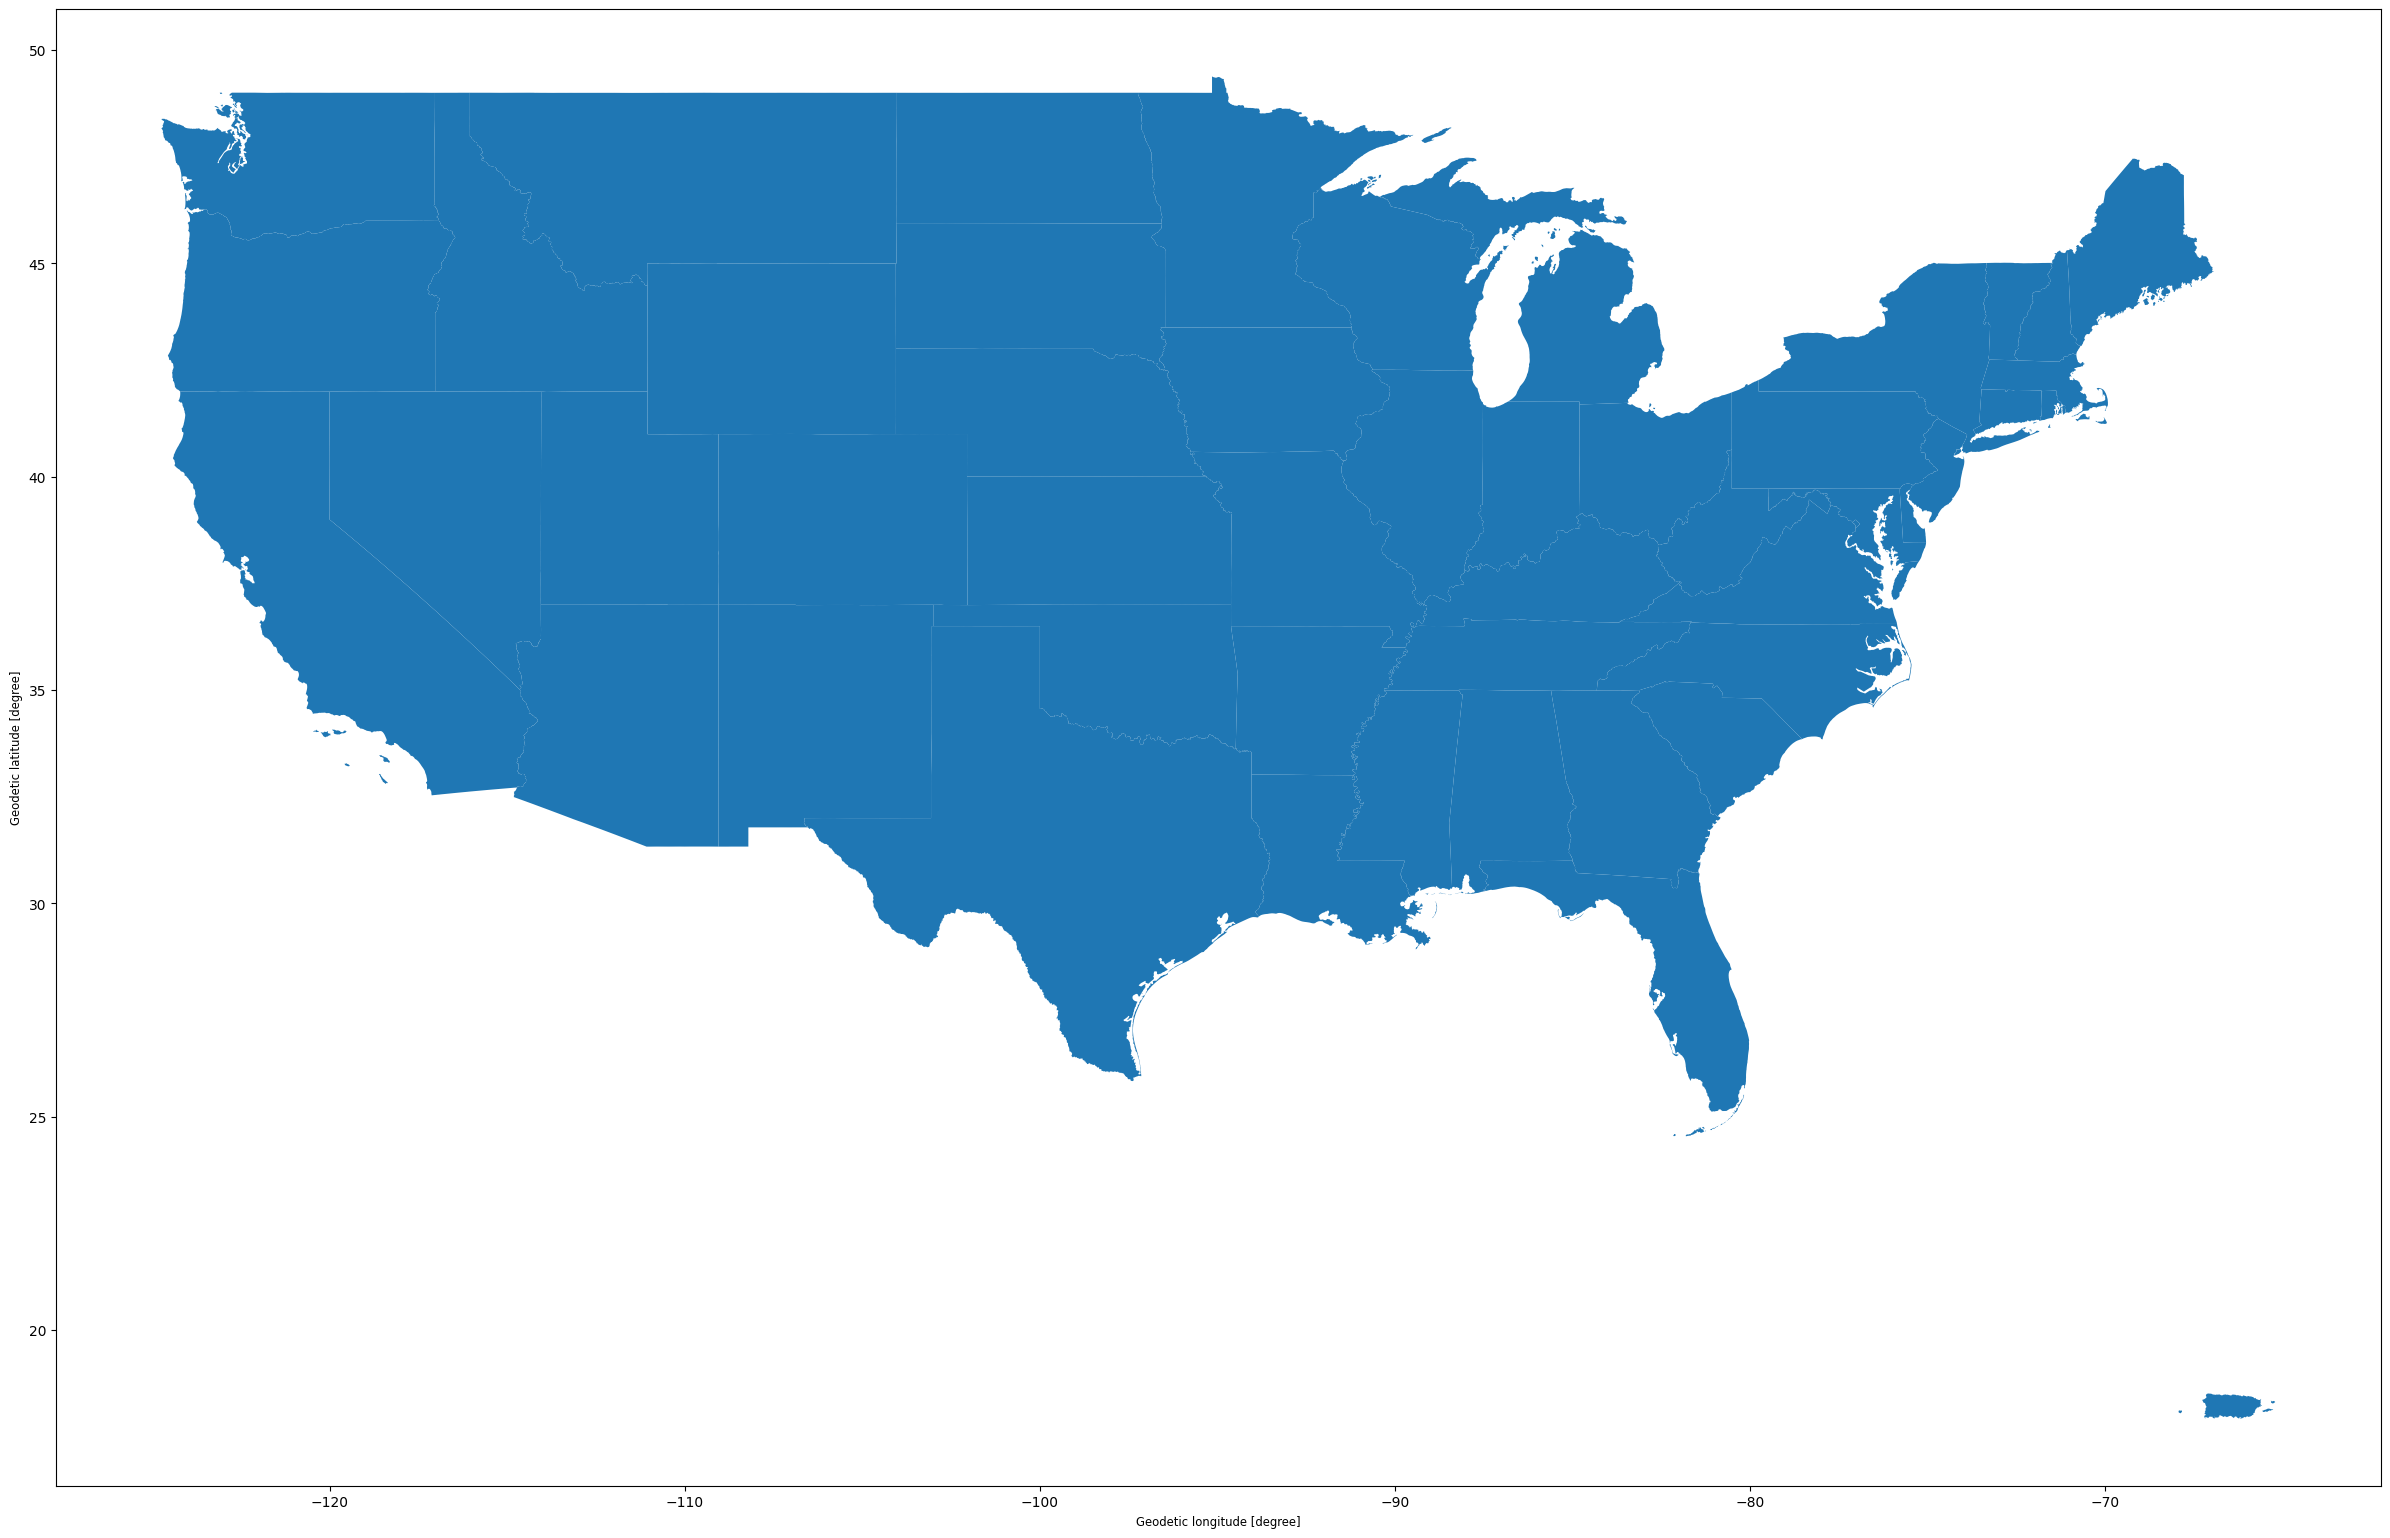

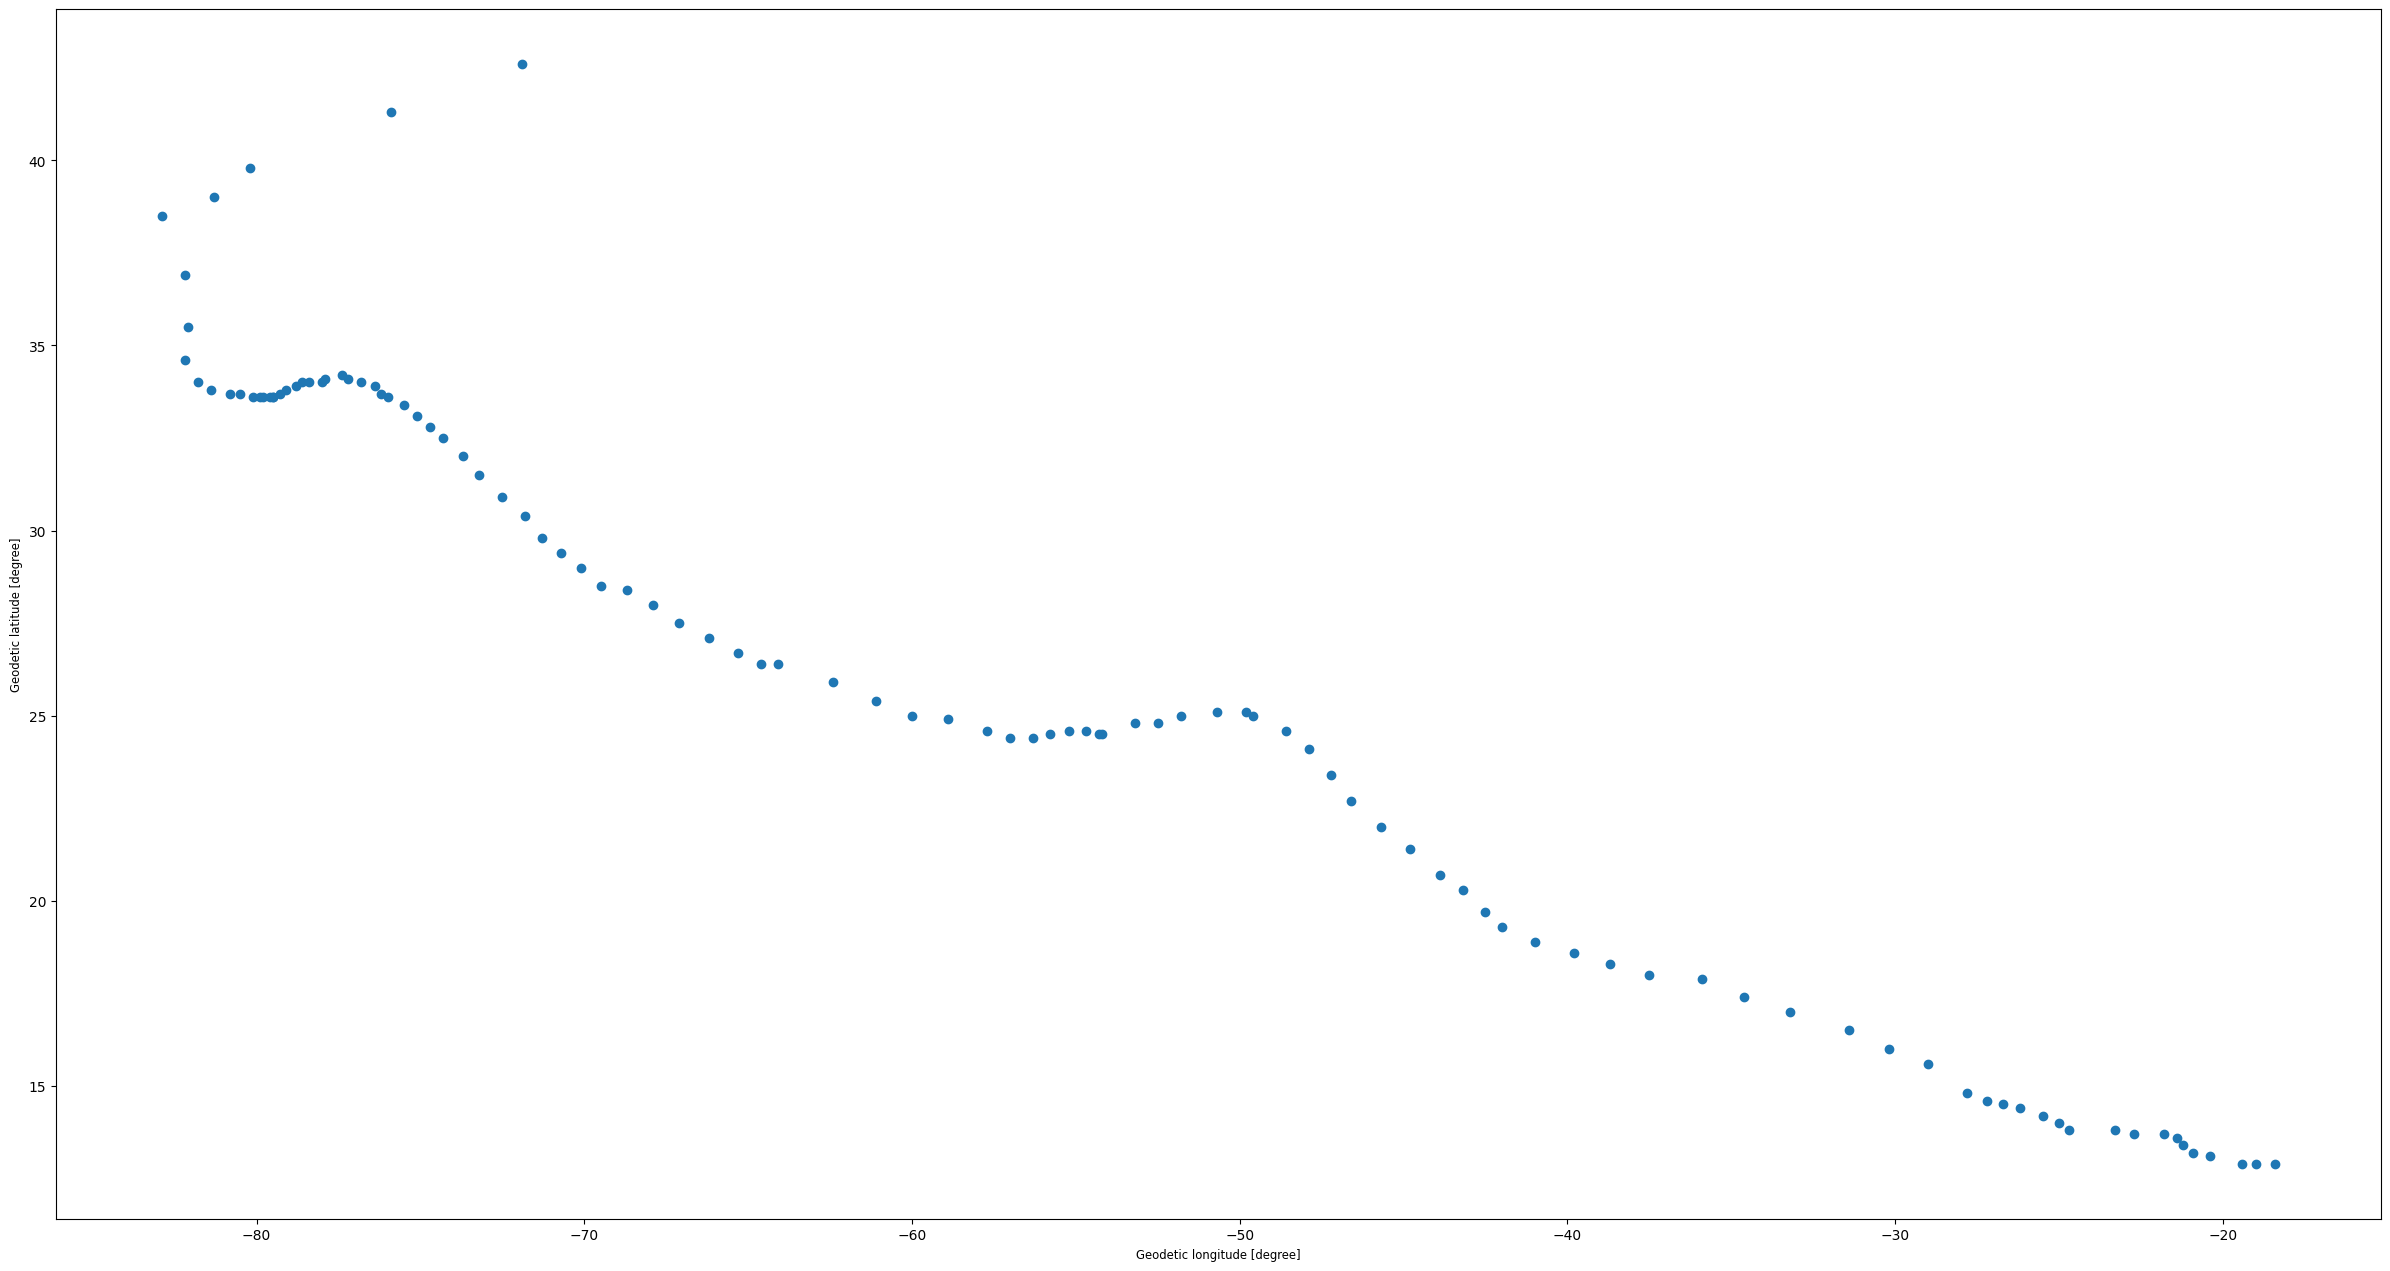

In [7]:
# Q6 : Plot to see the hurricane overlay the US map, with the hurricane position on top --> ERROR two graphs
US = country[~country["NAME"].isin(["Alaska","Hawaii"])].plot(figsize=(30,20))

gdf_florence.plot(figsize=(30,20))


**ERROR** : The two graphs are shown but are not overlapping with each other

**Solution** : We need to find a way to tell python to use the same axes for the two graphs. To do so we will create a subplot and for each plot we are going to precise that ax=ax

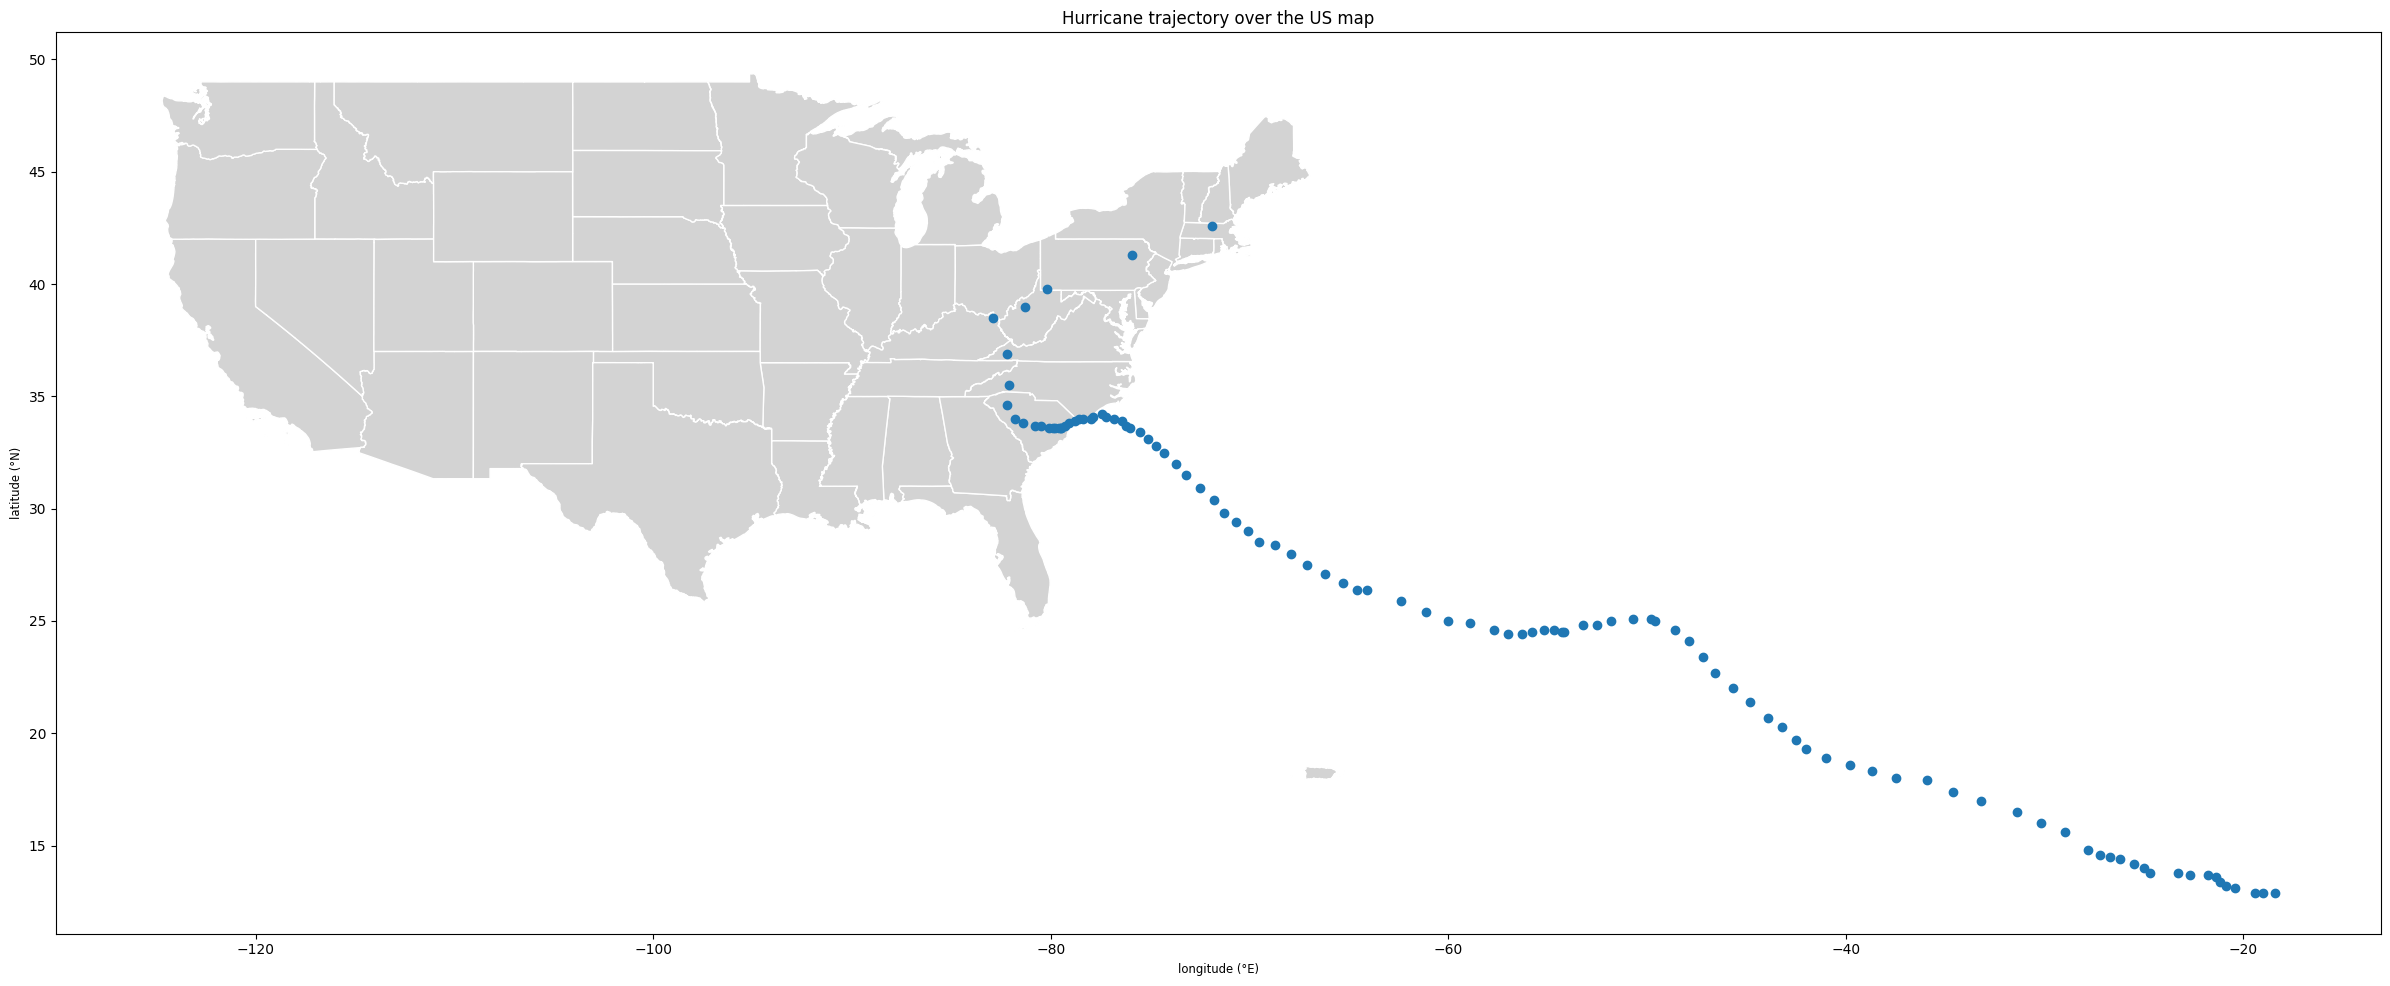

In [8]:
US = country[~country["NAME"].isin(["Alaska","Hawaii"])]

fig, ax = plt.subplots(figsize=(30,20))
US.plot(ax=ax, color="lightgrey", linewidth=1, edgecolor="w")
gdf_florence.plot(ax=ax)
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane trajectory over the US map")

plt.show()


In [9]:
# Q7 : Check the coordinate reference system of the data
print(US.crs)
print(gdf_florence.crs)
print(US.crs == gdf_florence.crs)

EPSG:4326
EPSG:4326
True


Text(0.5, 1.0, 'Hurricane trajectory over the US map')

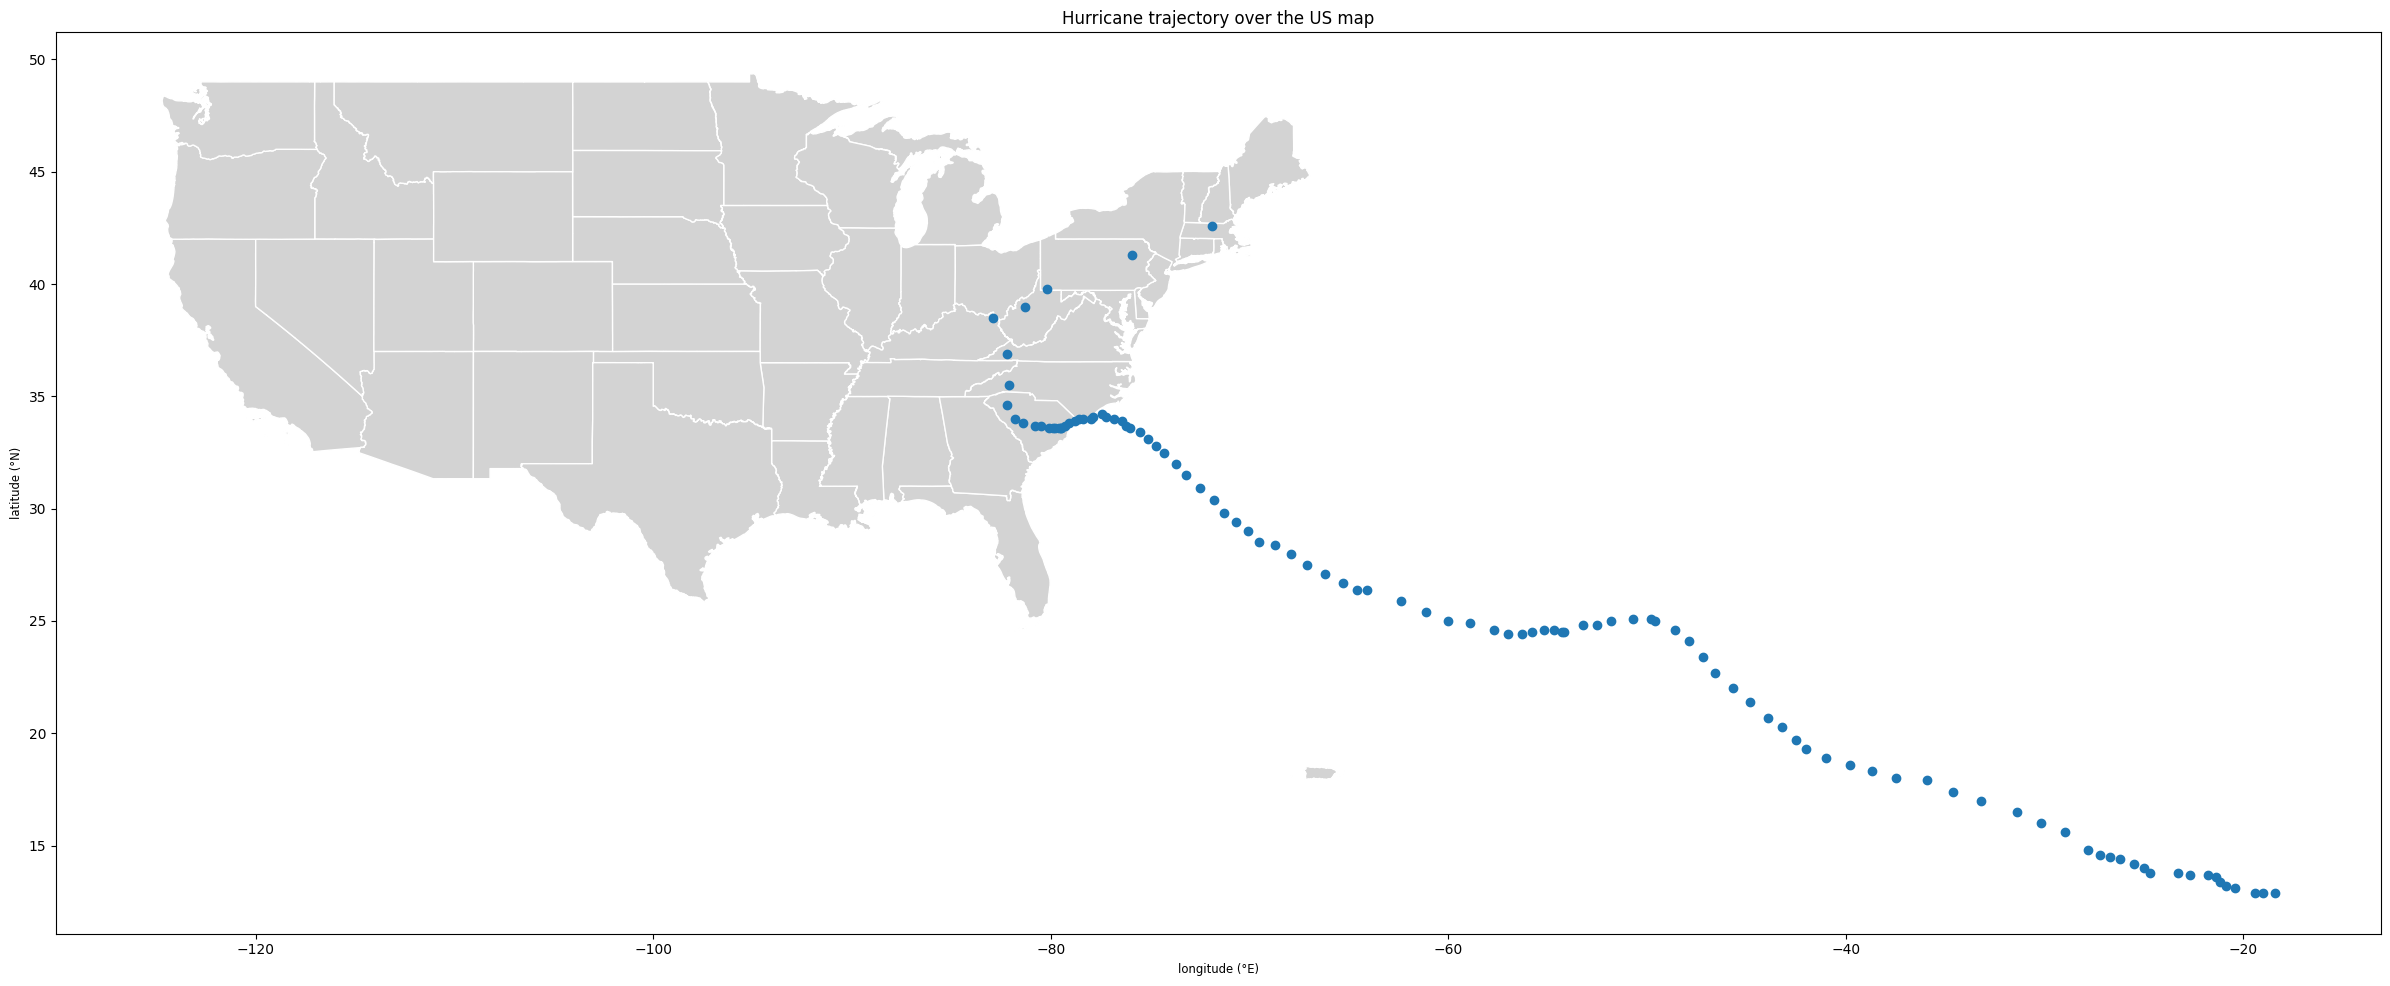

In [10]:
# Q8 :
# Plot the US states without Alaska and Hawaii
US = country[~country["NAME"].isin(["Alaska","Hawaii"])]

fig, ax = plt.subplots(figsize=(30,20))
US.plot(ax=ax, color="lightgrey", linewidth=1, edgecolor="w")
gdf_florence.plot(ax=ax)
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane trajectory over the US map")


For the second part of Question 8: It is asked to annotate the US states with their names. To do so I've used the documentation from matplotlib annotations : [matplotlib.org](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.annotate.html$0)


matplotlib.pyplot.annotate(text, xy, xytext=None, xycoords='data', textcoords=None, arrowprops=None, annotation_clip=None, **kwargs)




/tmp/ipykernel_2048/1384404863.py:14: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  state_centers = US.centroid


ValueError: too many values to unpack (expected 2)

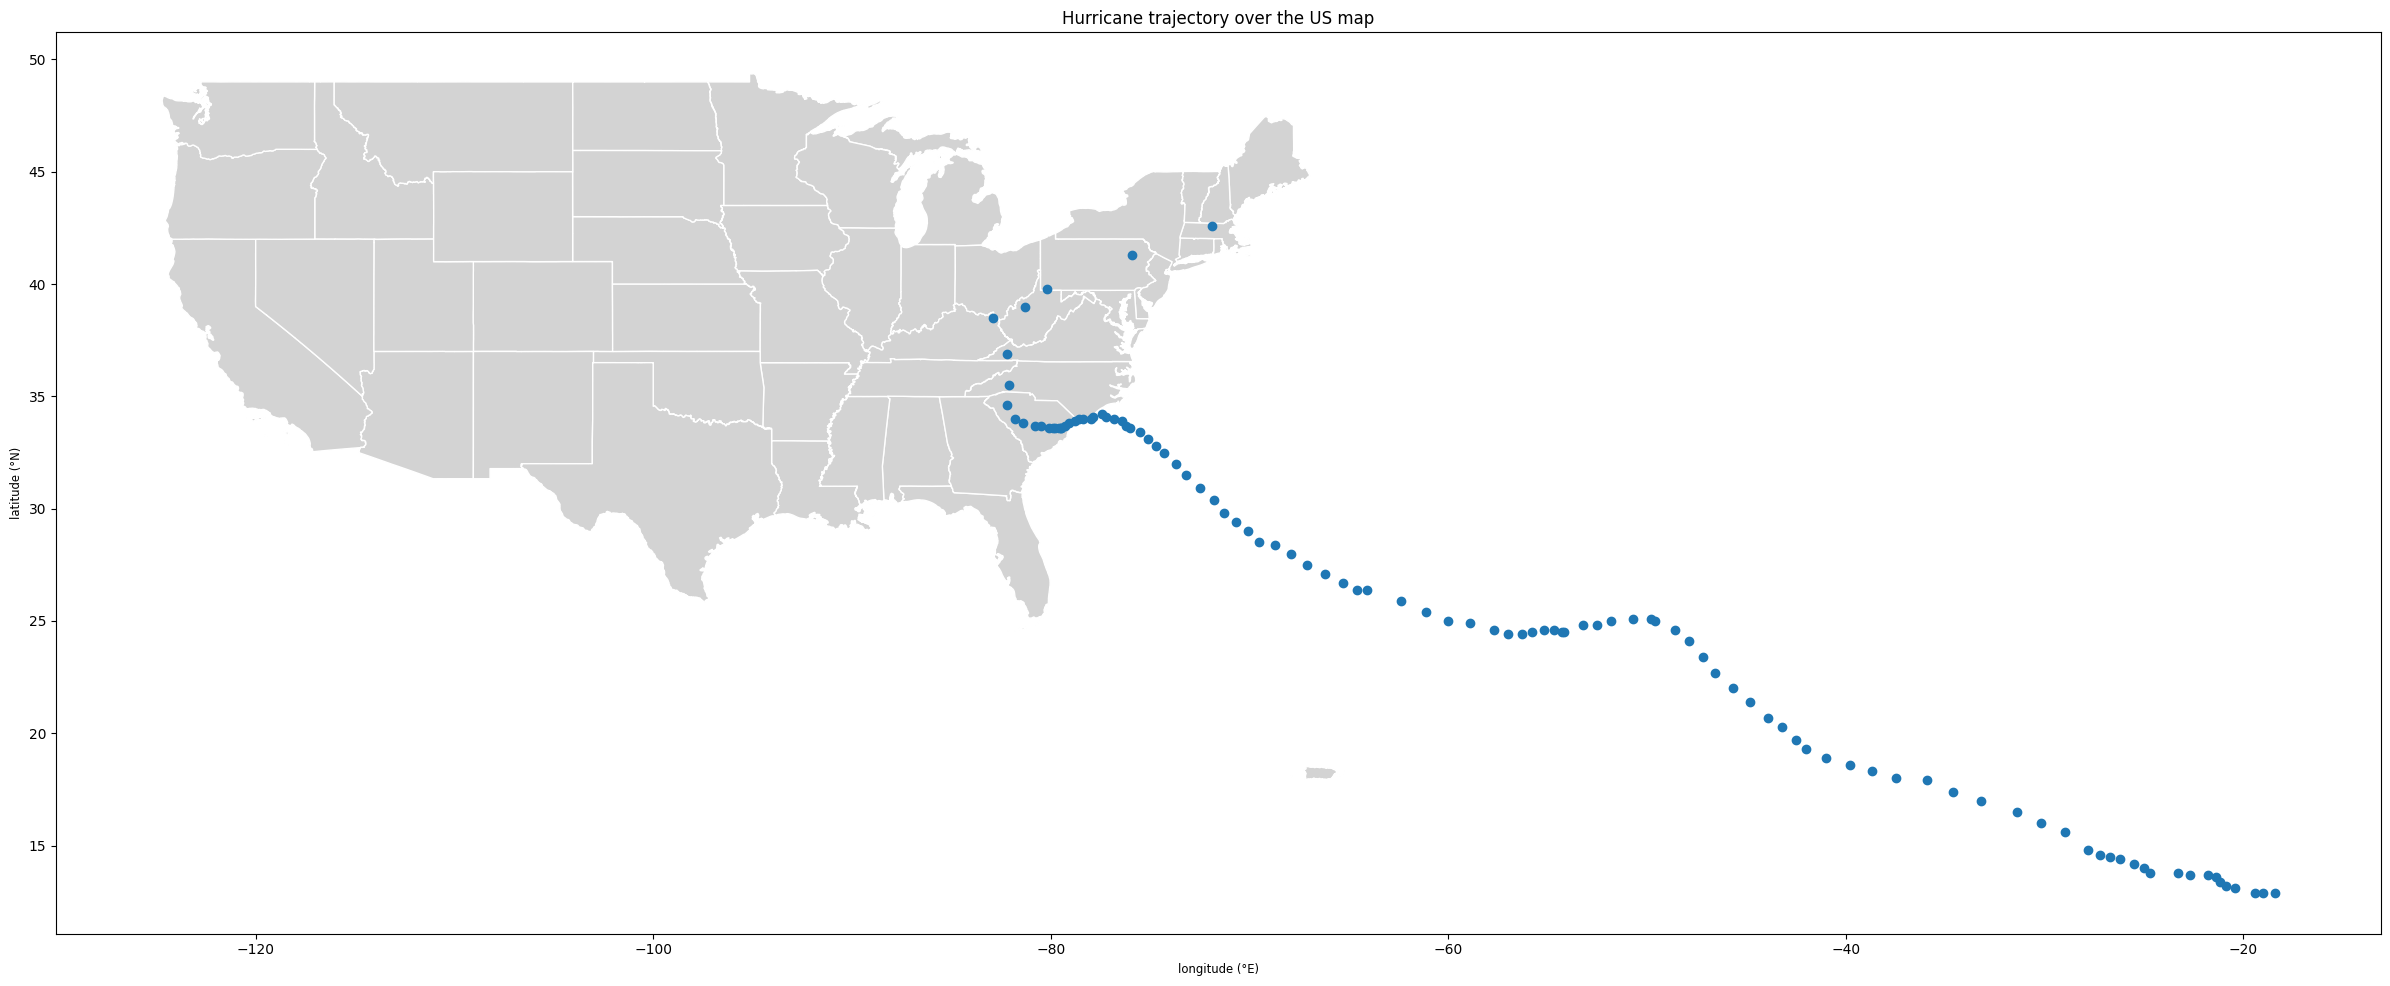

In [11]:
# Q8 :
# Plot the US states without Alaska and Hawaii
US = country[~country["NAME"].isin(["Alaska","Hawaii"])]

fig, ax = plt.subplots(figsize=(30,20))
US.plot(ax=ax, color="lightgrey", linewidth=1, edgecolor="w")
gdf_florence.plot(ax=ax)
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane trajectory over the US map")


# annotate the US states with their names
state_centers = US.centroid
plt.annotate(country['NAME'], state_centers)



ERROR : There us too many values in state_centers to run 'annotate'.

Solution : We need to create a loop for annotate to go through each state_centers

/tmp/ipykernel_2048/418882120.py:14: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  state_centers = US.centroid


TypeError: 'GeoSeries' object is not callable

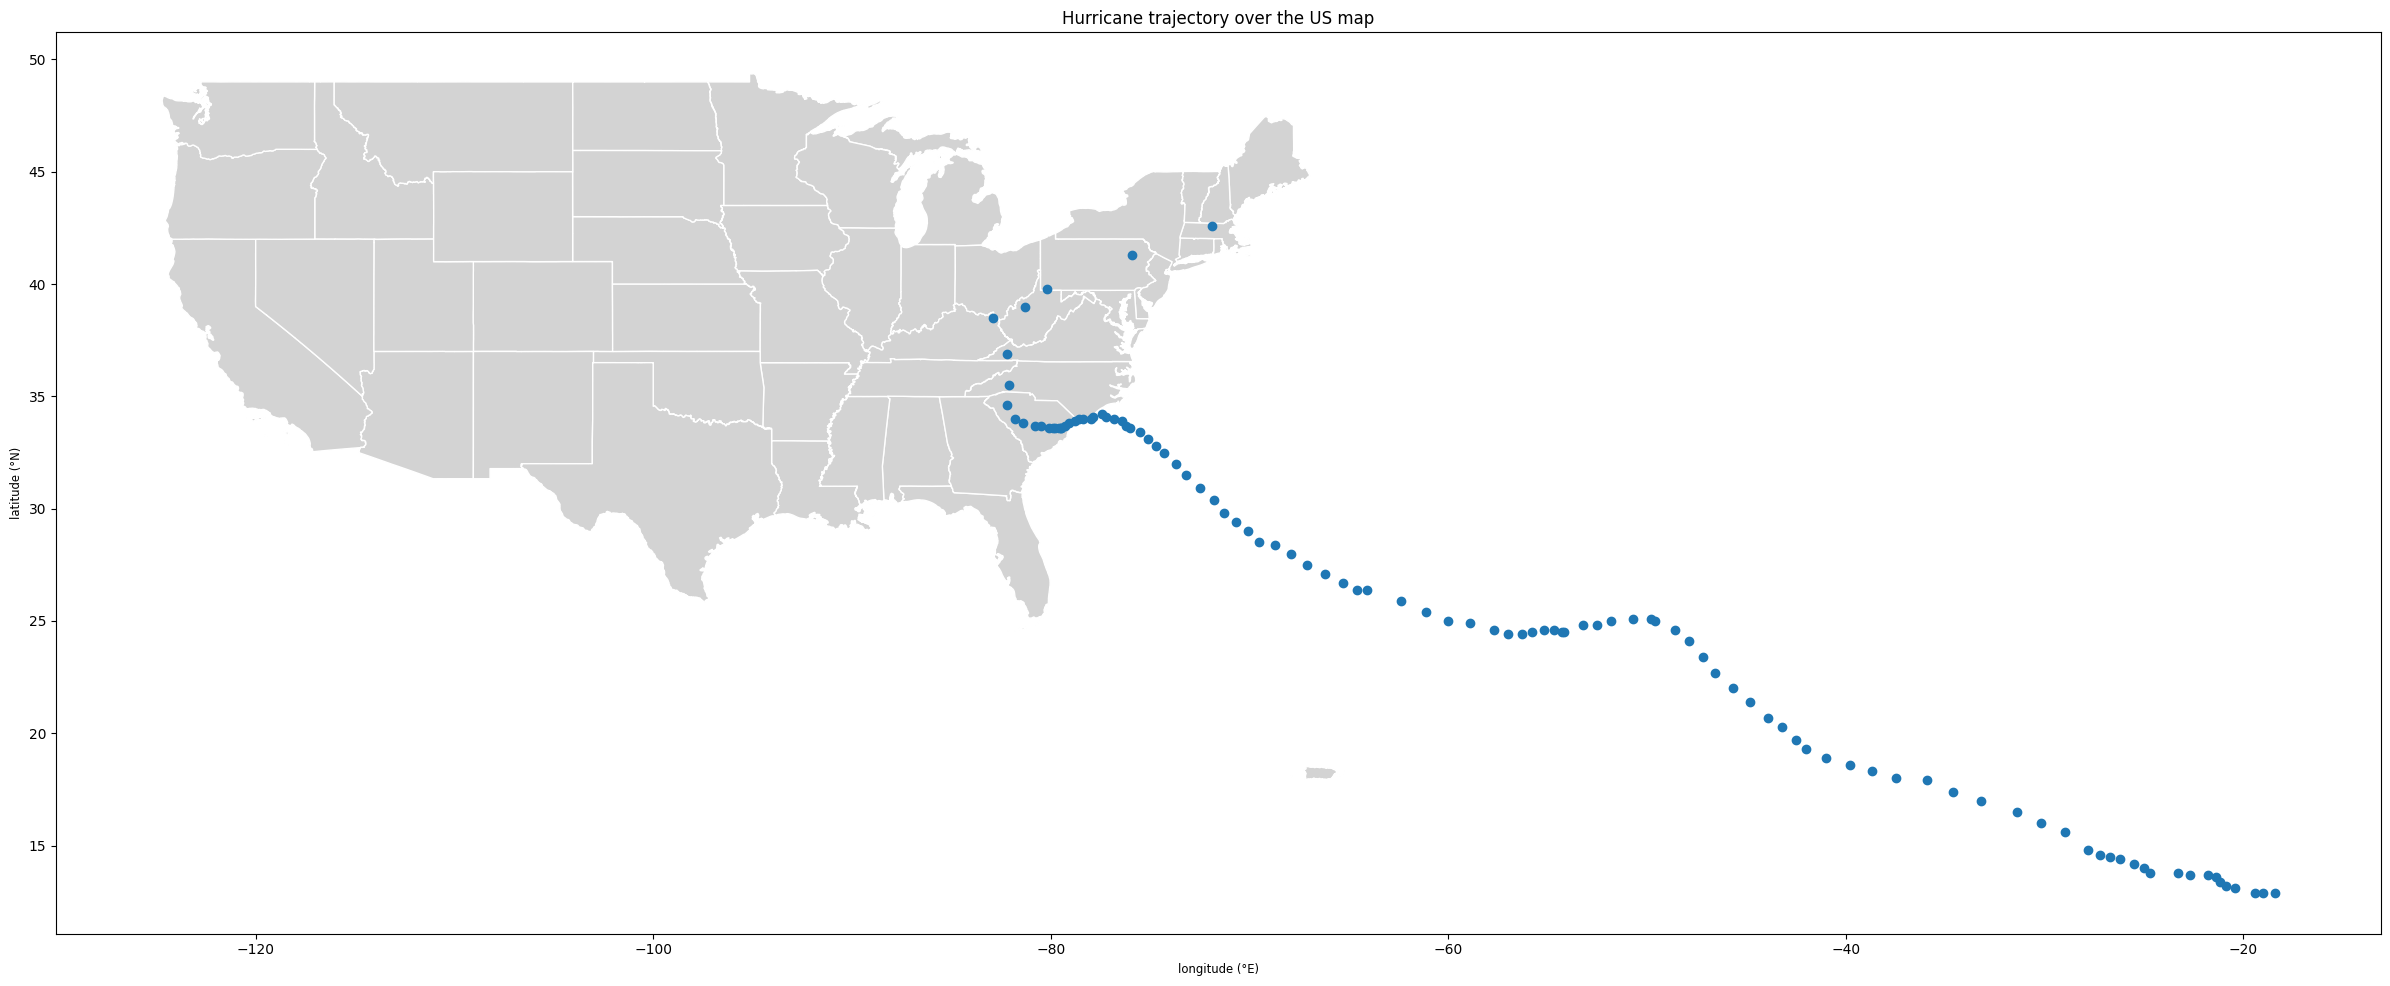

In [12]:
# Q8 :
# Plot the US states without Alaska and Hawaii
US = country[~country["NAME"].isin(["Alaska","Hawaii"])]

fig, ax = plt.subplots(figsize=(30,20))
US.plot(ax=ax, color="lightgrey", linewidth=1, edgecolor="w")
gdf_florence.plot(ax=ax)
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane trajectory over the US map")


# annotate the US states with their names
state_centers = US.centroid

for point in state_centers :
  plt.annotate(country['NAME'], state_centers(point))




 As I can't seem to find what function to use to create a loop where annotate can give one name for each state_centers, I asked Claude to indicate to me what function could solve this problem. It told make a loop with zip(names, point)



/tmp/ipykernel_1116/1667820284.py:14: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  state_centers = US.centroid


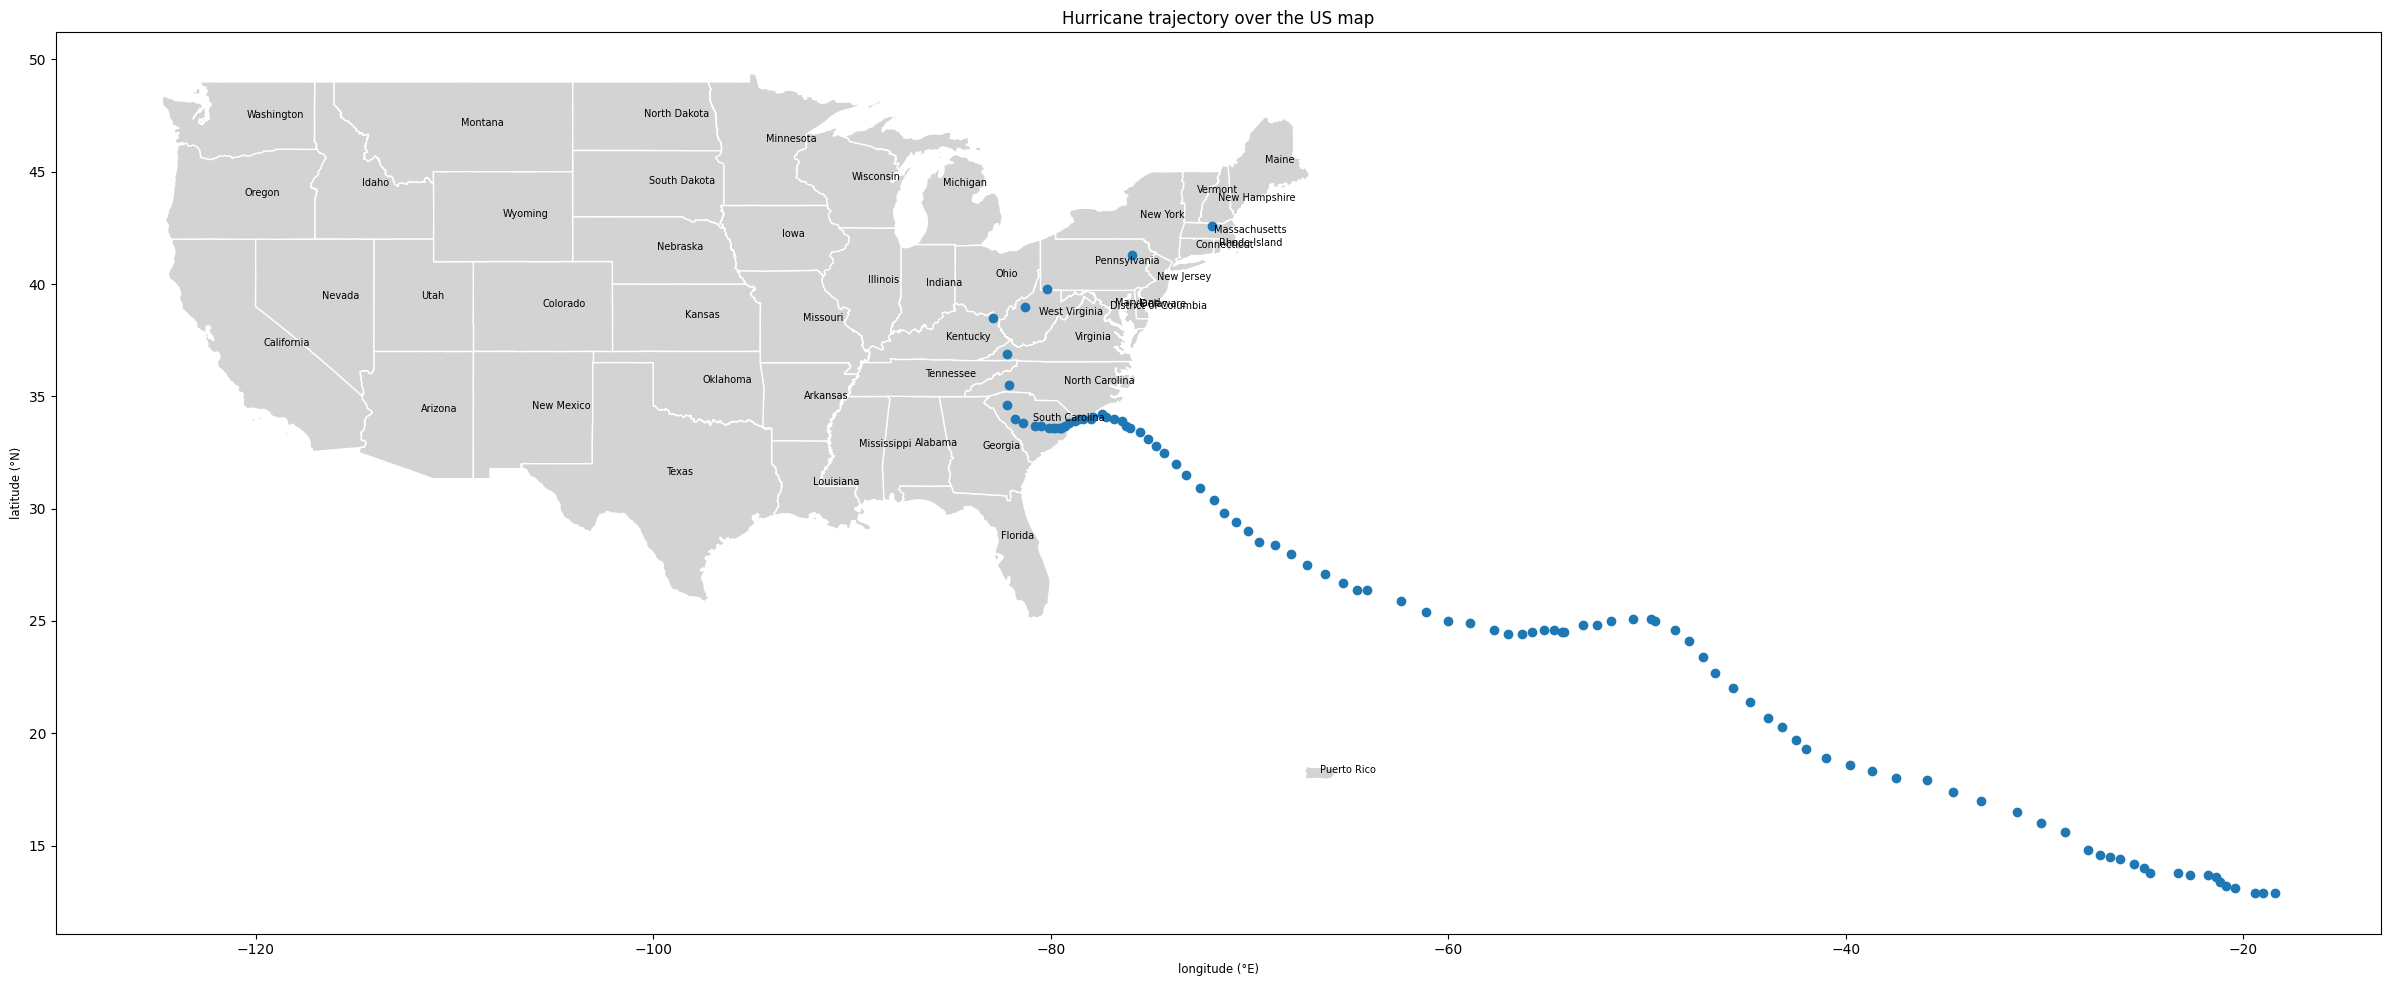

Text(0.5, 1.0, 'Hurricane inside the US map')

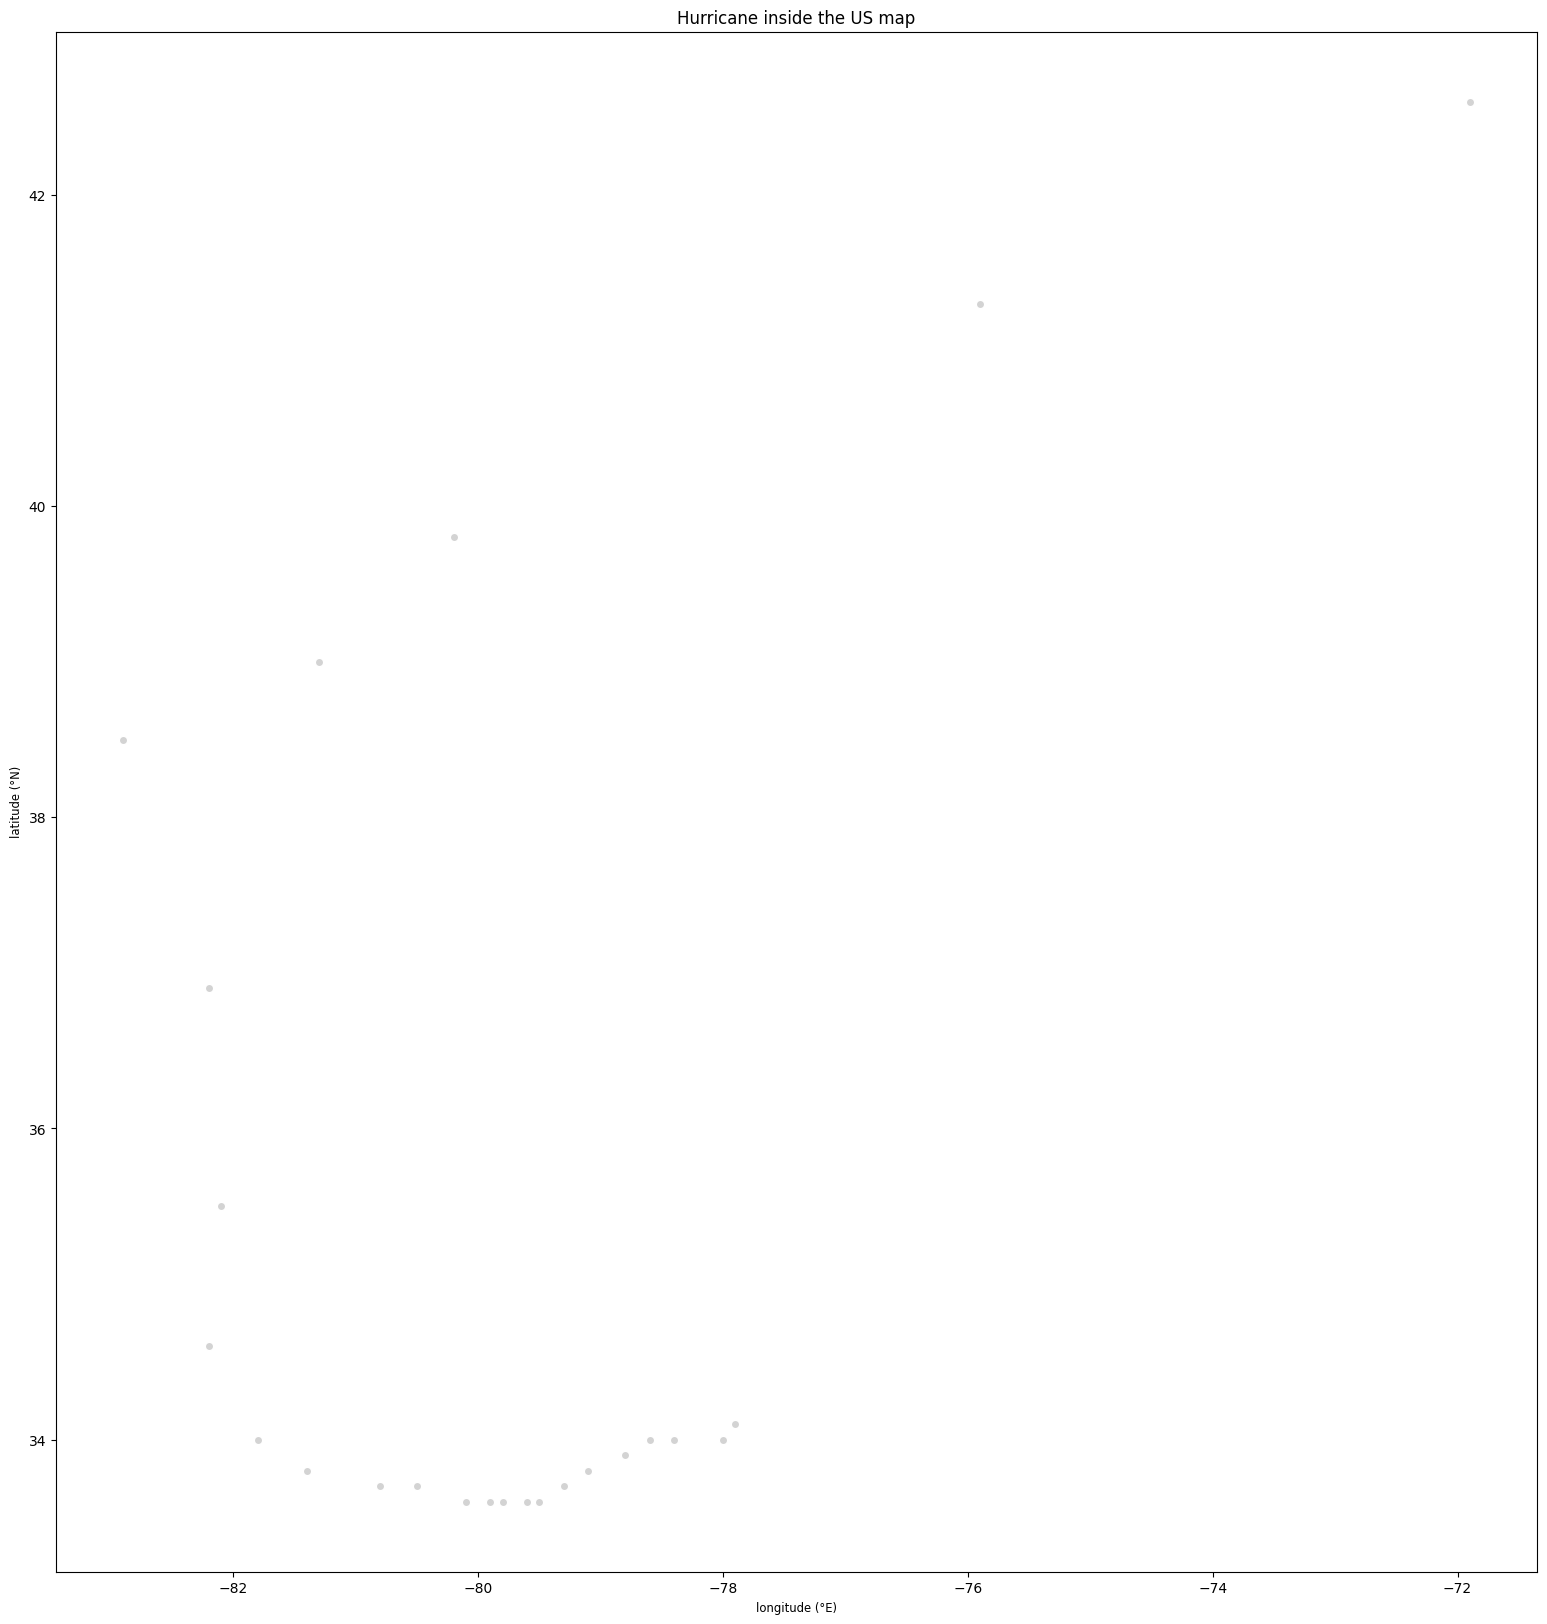

In [22]:
# Q8 :
# Plot the US states without Alaska and Hawaii
US = country[~country["NAME"].isin(["Alaska","Hawaii"])]

fig, ax = plt.subplots(figsize=(30,20))
US.plot(ax=ax, color="lightgrey", linewidth=1, edgecolor="w")
gdf_florence.plot(ax=ax)
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane trajectory over the US map")


# annotate the US states with their names
state_centers = US.centroid
for NAME, pt in zip(US['NAME'], state_centers):         # creates a loop where zip associates the names to the state_centers coordinates
    ax.annotate(NAME, xy=(pt.x, pt.y), fontsize=7)      # annotates each name with its polygone coordinate

plt.show()

# select the hurricane trajectory points inside the US boundary with the overlay operation
hurricane_US = gpd.overlay(gdf_florence, US, how="intersection")

# plot the hurricane trajectory inside the US boundary
fig, ax = plt.subplots(figsize=(30,20))
hurricane_US.plot(ax=ax, color="lightgrey", linewidth=1, edgecolor="w")
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane inside the US map")

**ERROR** : For the second plot, we only have the points of the hurricane but not the map of the US

**Solution** : The hurricane_US only gives os the point of the hurricane inside the US, but we still need to plot the US map, to do so we can add a second plot in the figure with the same axes


/tmp/ipykernel_2048/1593126934.py:13: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  state_centers = US.centroid


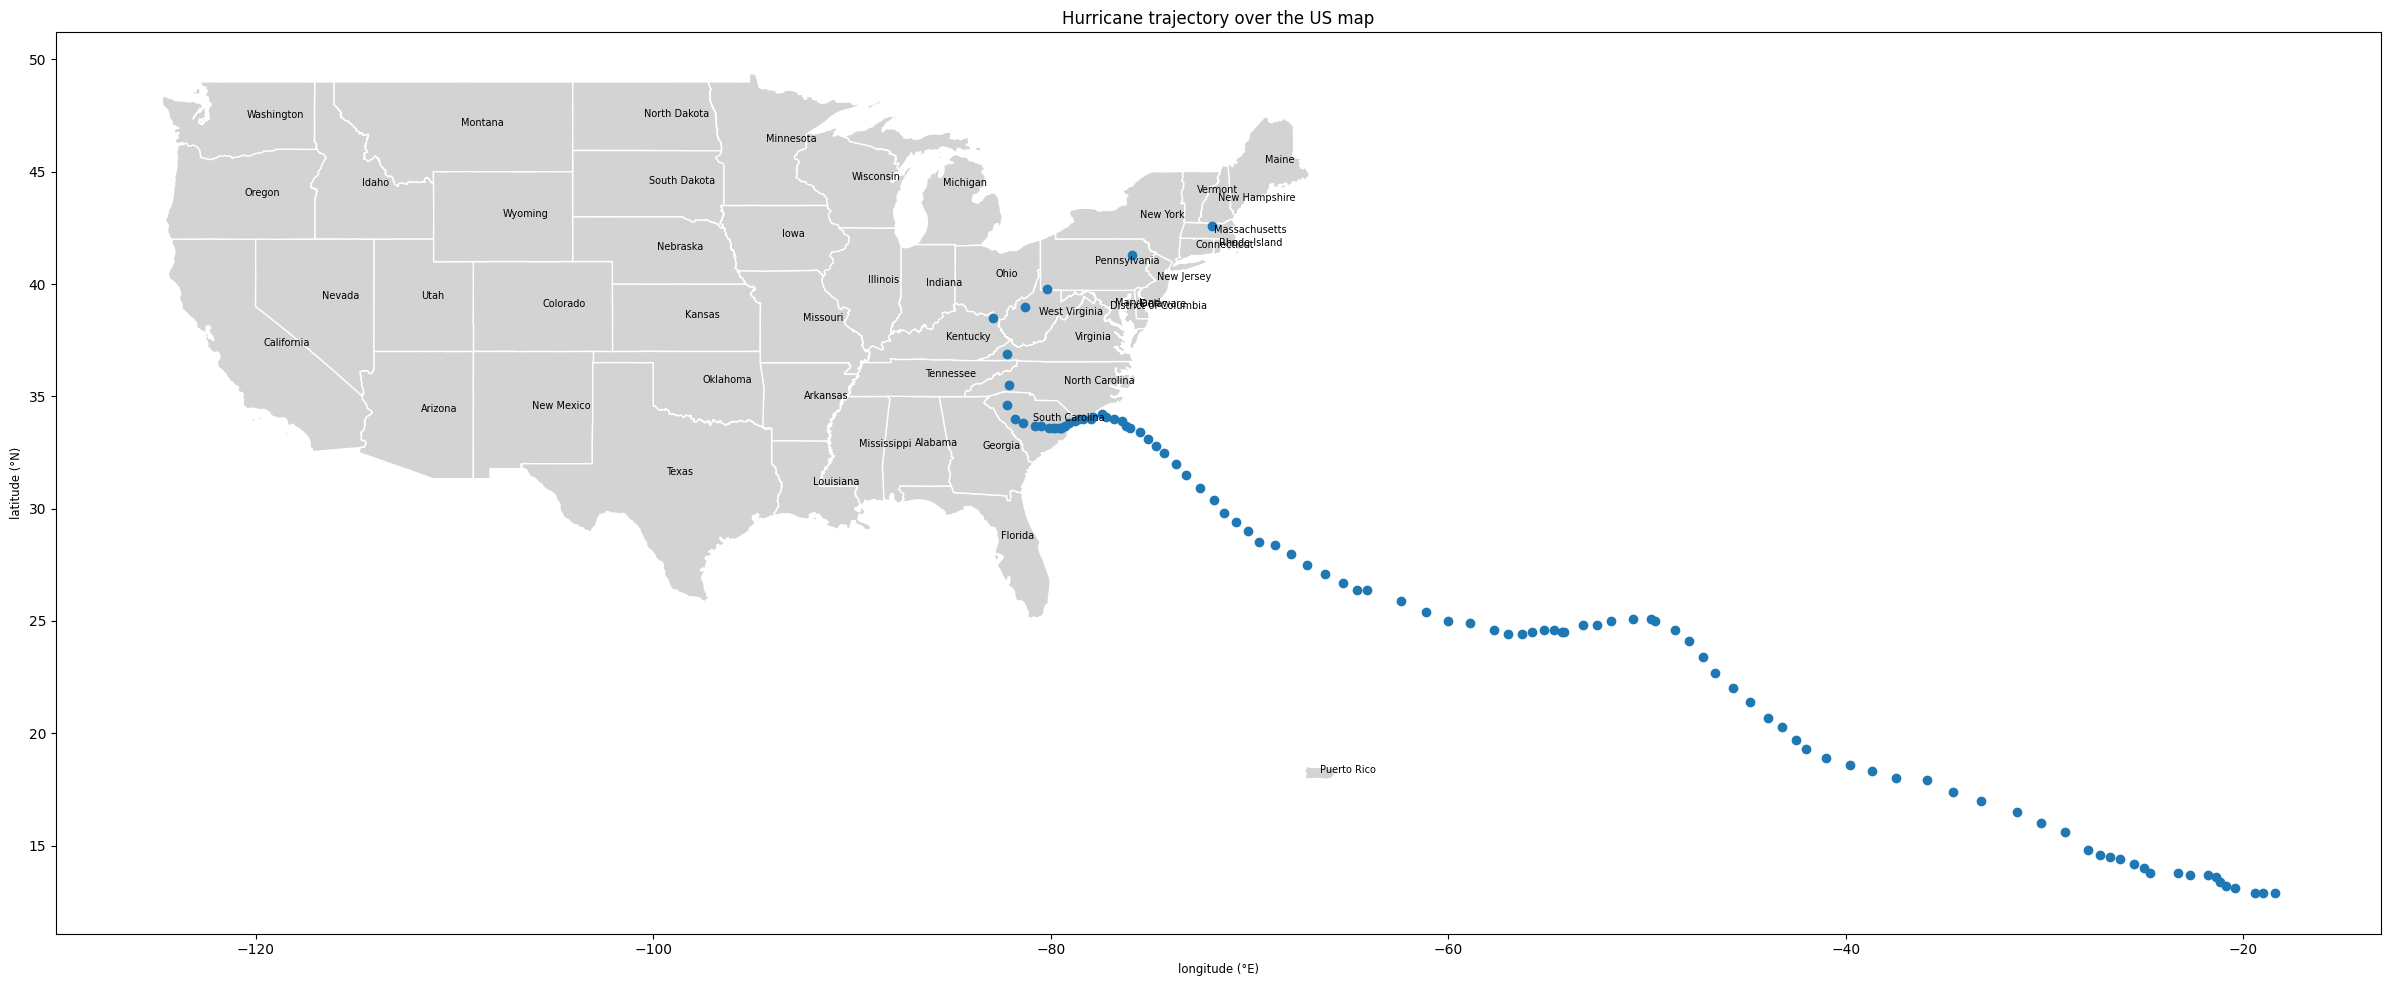

Text(0.5, 1.0, 'Hurricane inside the US map')

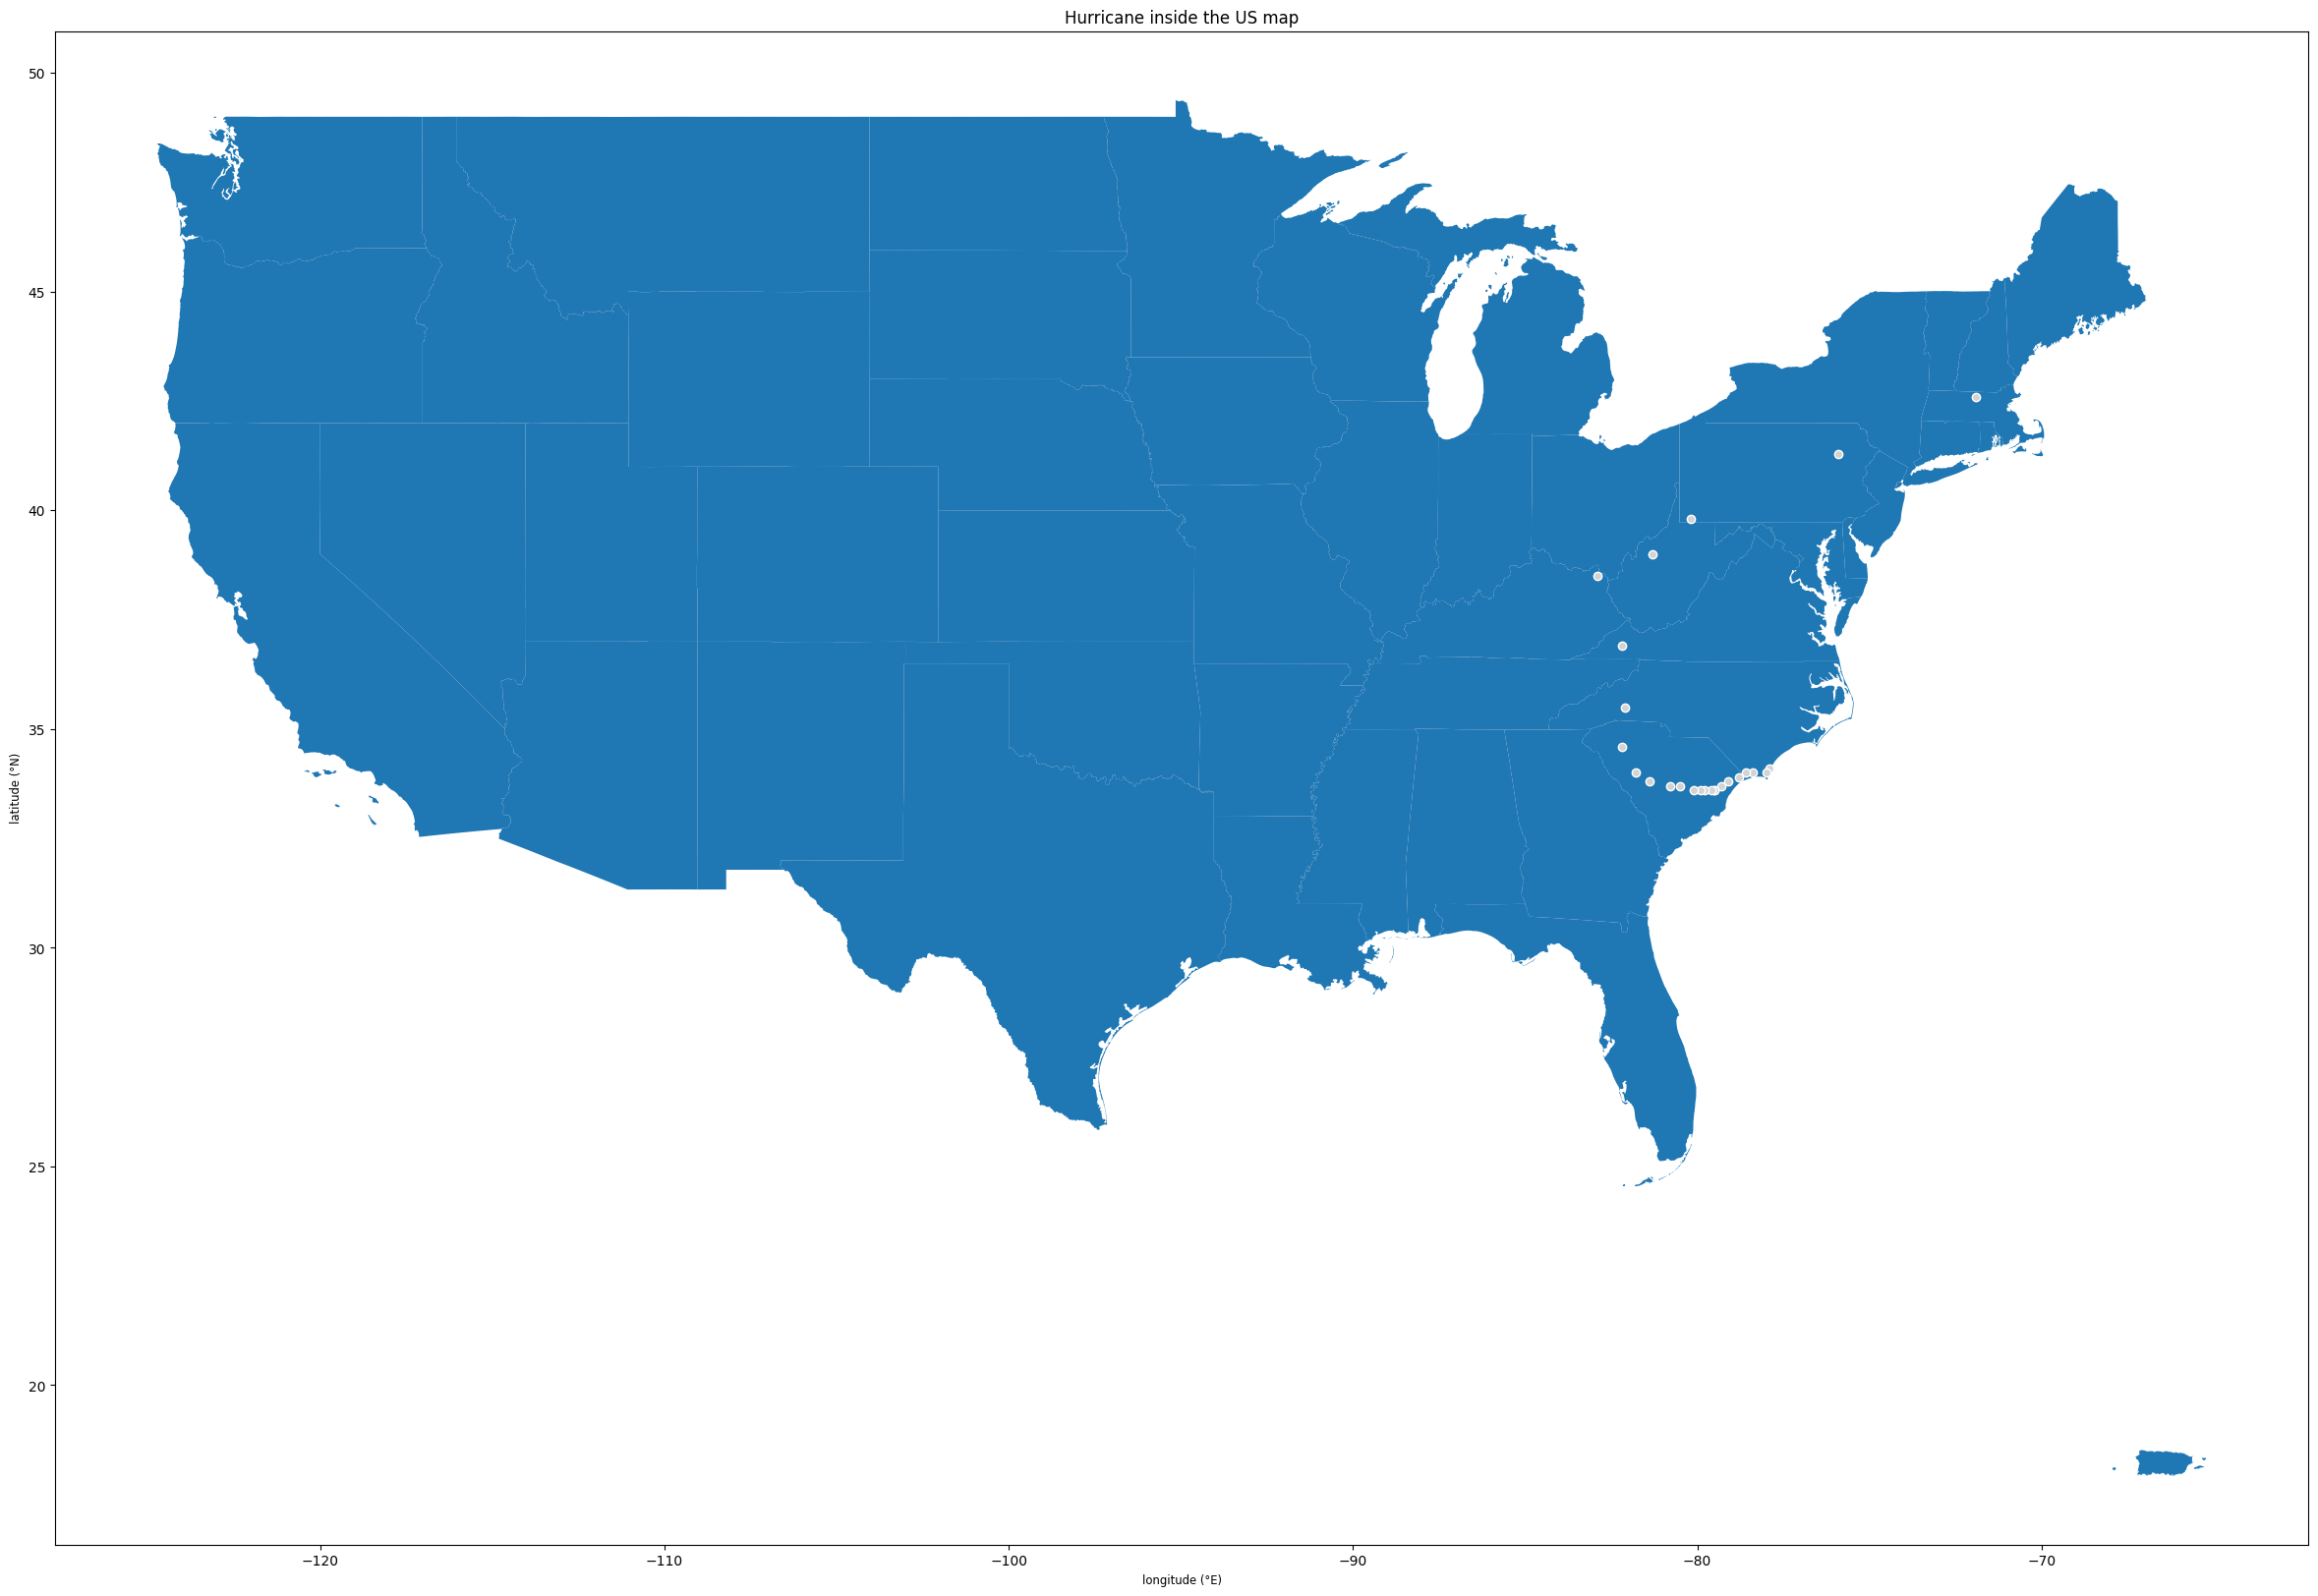

In [15]:
# Q8 :
# Plot the US states without Alaska and Hawaii
US = country[~country["NAME"].isin(["Alaska","Hawaii"])]

fig, ax = plt.subplots(figsize=(30,20))
US.plot(ax=ax, color="lightgrey", linewidth=1, edgecolor="w")
gdf_florence.plot(ax=ax)
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane trajectory over the US map")

# annotate the US states with their names
state_centers = US.centroid
for NAME, pt in zip(US['NAME'], state_centers):         # creates a loop where zip associates the names to the state_centers coordinates
    ax.annotate(NAME, xy=(pt.x, pt.y), fontsize=7)      # annotates each name with its polygone coordinate

plt.show()

# select the hurricane trajectory points inside the US boundary with the overlay operation
hurricane_US = gpd.overlay(gdf_florence,US, how="intersection")

# plot the hurricane trajectory inside the US boundary
fig, ax = plt.subplots(figsize=(30,20))
US.plot(ax=ax)
hurricane_US.plot(ax=ax, color="lightgrey", linewidth=1, edgecolor="w")
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane inside the US map")

/tmp/ipykernel_2048/1734251899.py:16: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  state_centers = US.centroid


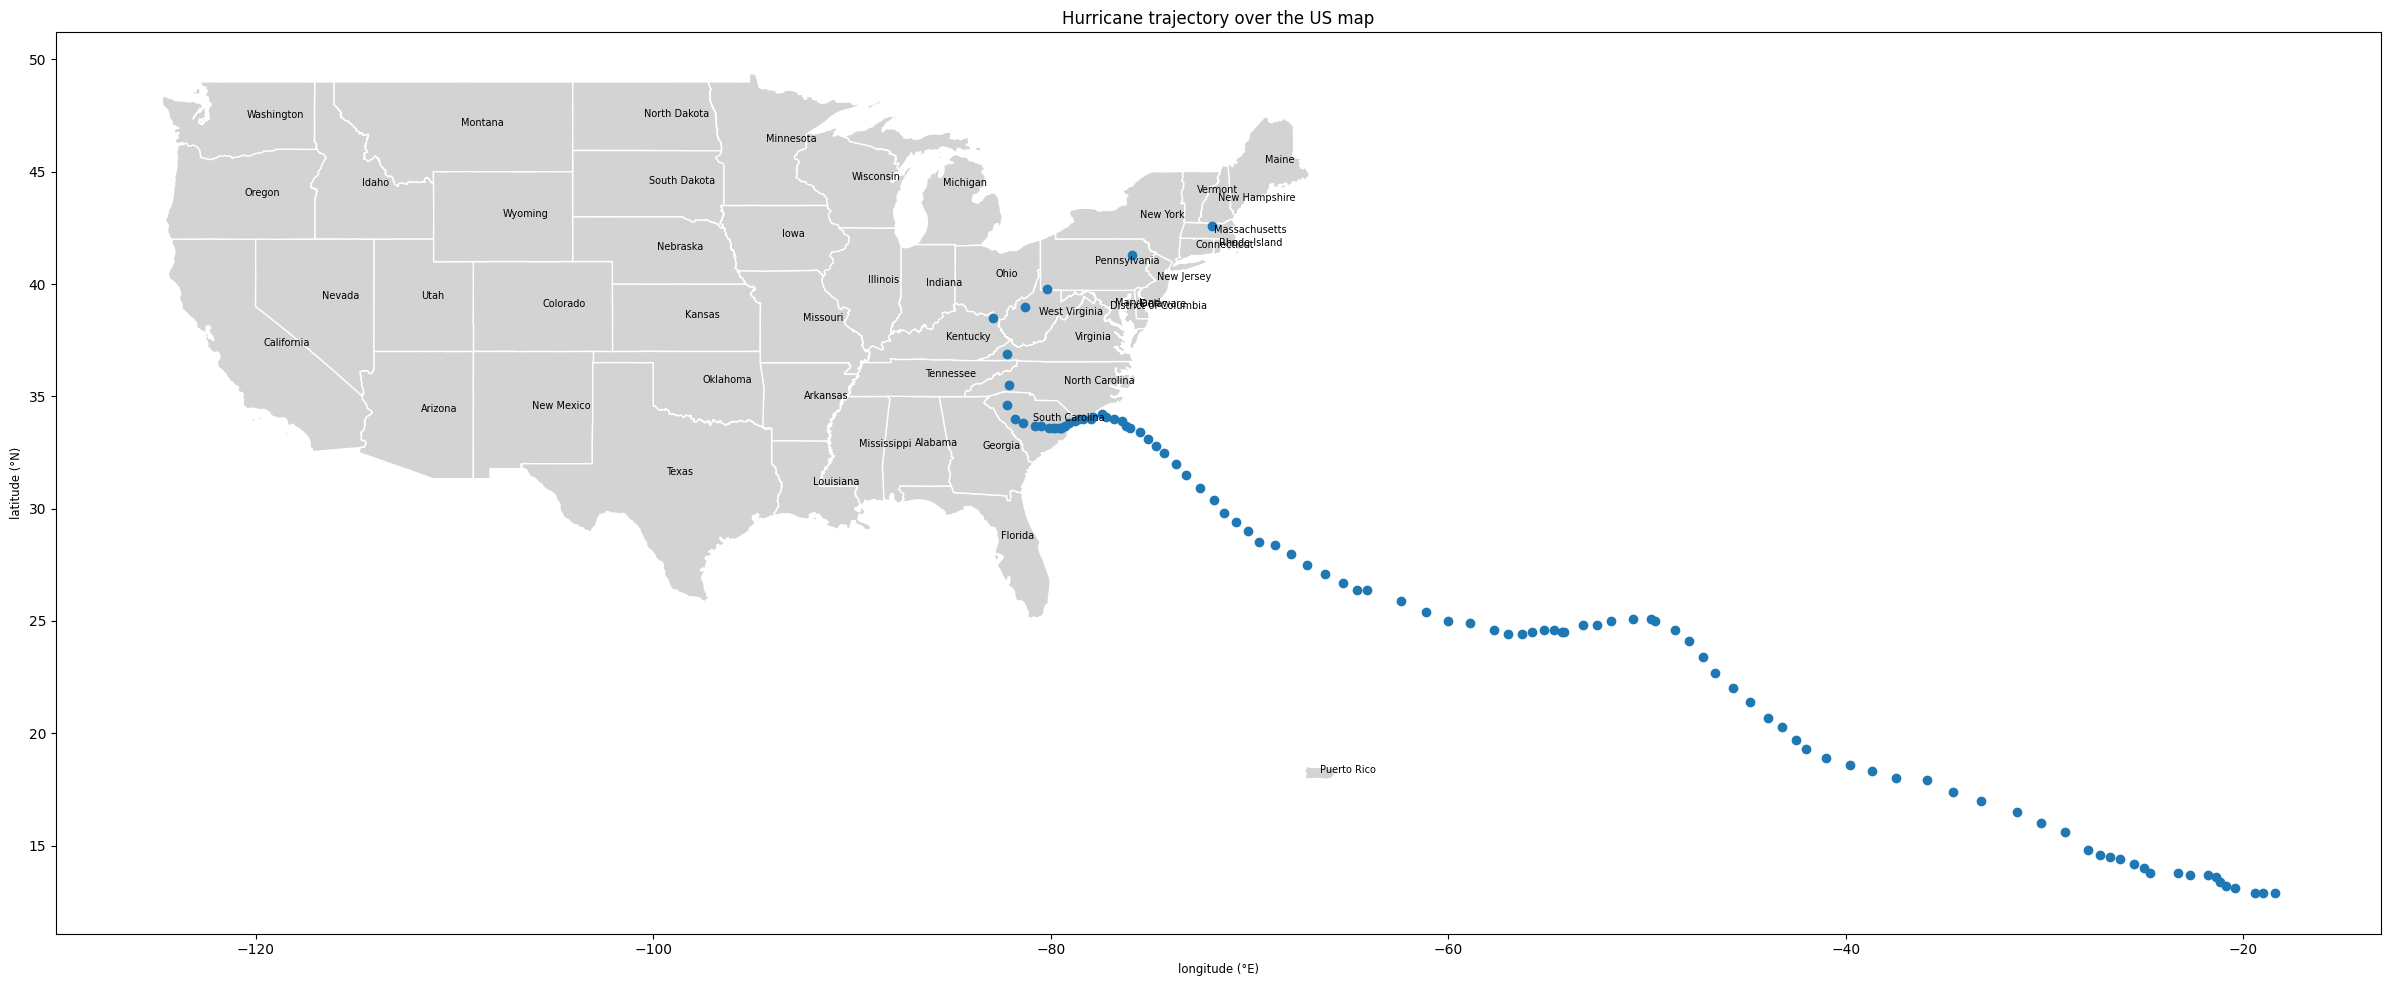

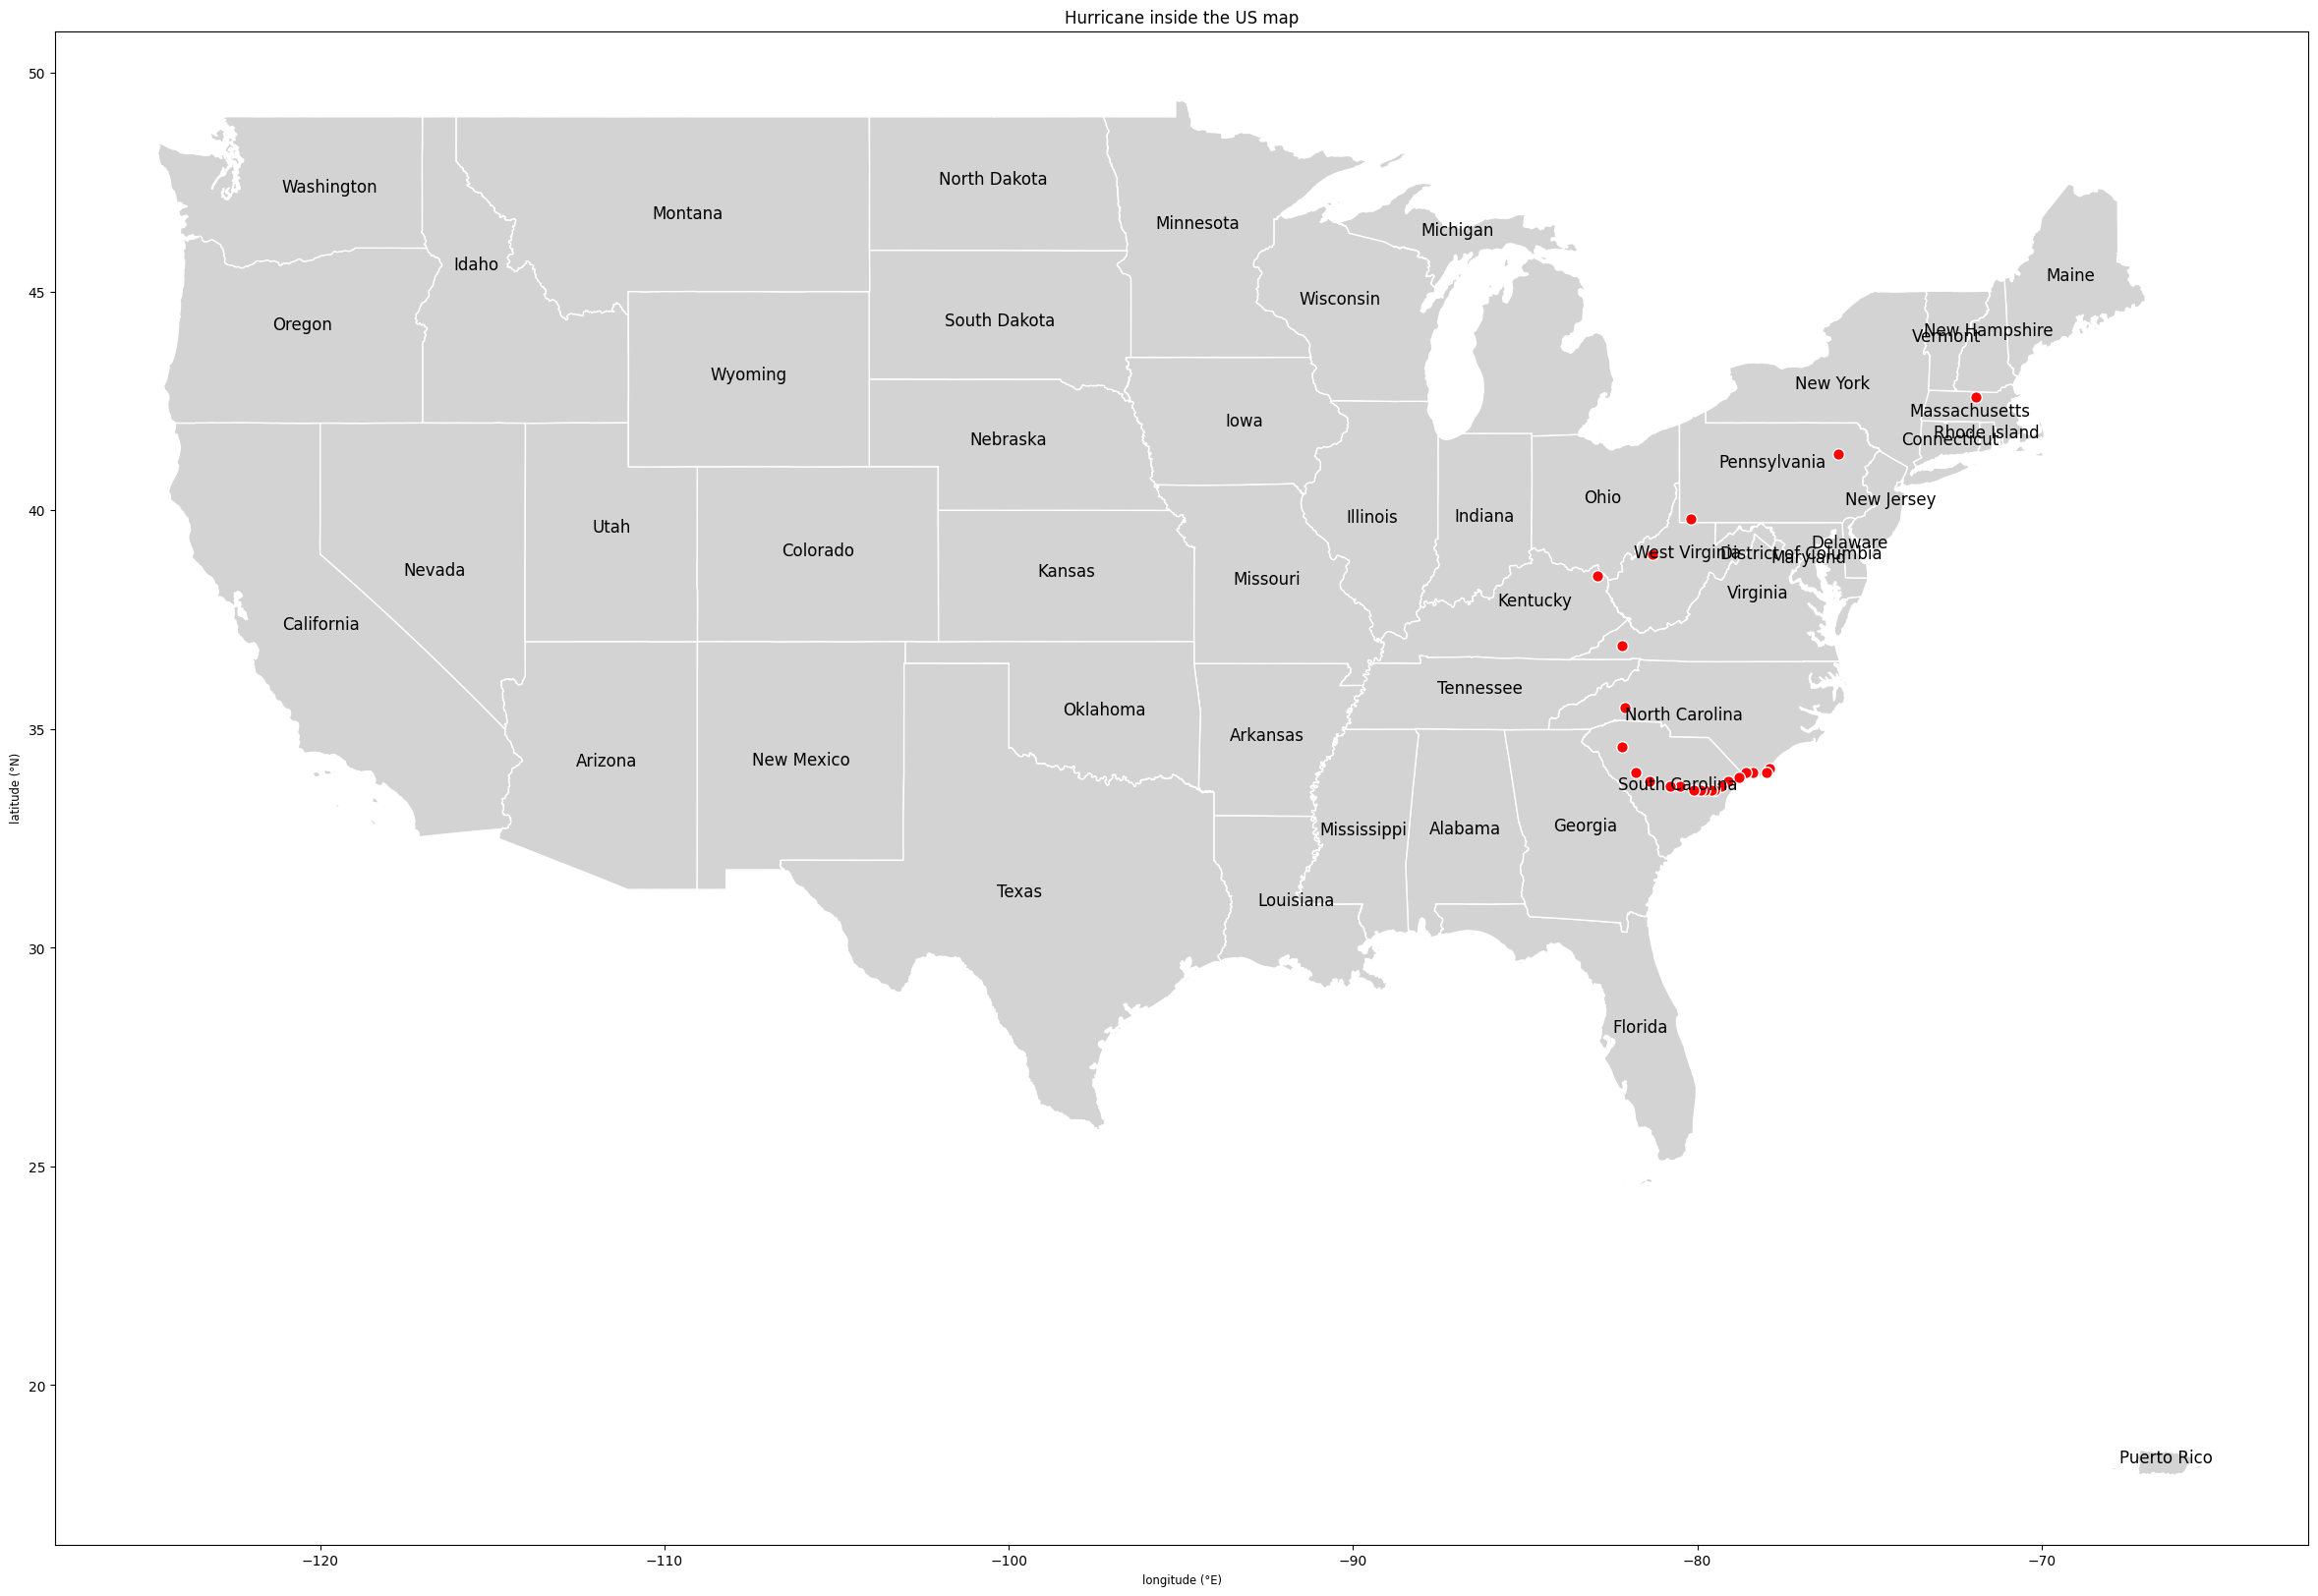

In [14]:
# Change of colour and point sizes to make it more visible

# Q8 :
# Plot the US states without Alaska and Hawaii
US = country[~country["NAME"].isin(["Alaska","Hawaii"])]

fig, ax = plt.subplots(figsize=(30,20))
US.plot(ax=ax, color="lightgrey", linewidth=1, edgecolor="w")
gdf_florence.plot(ax=ax)
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane trajectory over the US map")


# annotate the US states with their names
state_centers = US.centroid
for NAME, pt in zip(US['NAME'], state_centers):         # creates a loop where zip associates the names to the state_centers coordinates
    ax.annotate(NAME, xy=(pt.x, pt.y), fontsize=7)      # annotates each name with its polygone coordinate

plt.show()

# select the hurricane trajectory points inside the US boundary with the overlay operation
hurricane_US = gpd.overlay(gdf_florence,US, how="intersection")

# plot the hurricane trajectory inside the US boundary
fig, ax = plt.subplots(figsize=(30,20))
US.plot(ax=ax, color="lightgrey", linewidth=1, edgecolor="w")
hurricane_US.plot(ax=ax, color="red", markersize=70, edgecolor="w")
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane inside the US map")

label_points = US.geometry.representative_point()
for name, pt in zip(US["NAME"], label_points):
    ax.annotate(name, xy=(pt.x, pt.y), ha="center", fontsize=12)

plt.show()